# Predicción de cancelaciones de reservas de hotel
**IA006 · Inteligencia Artificial · Proyecto del segundo corte (implementación)**

Autores: Rafael Antonio Arias Monsalve · Cristian Julián Peña

Docente: Ph.D. Andrés Felipe Jerez Ariza

Este cuaderno ejecuta el proceso que se propuso en el primer corte: limpieza, análisis exploratorio, ingeniería y reducción de variables, entrenamiento y comparación de modelos. Al final se guarda el modelo que usa la aplicación de Streamlit.

**Contenido**
1. Contexto y continuidad
2. Limpieza de datos
3. Análisis exploratorio
4. Ingeniería de variables
5. Reducción de dimensionalidad (PCA)
6. Modelado y evaluación
7. Resultados, conclusiones y limitaciones
8. Artefactos para el despliegue

## 0. Preparación del entorno
La primera celda escribe el archivo `model.py`, que reúne como funciones la ingeniería de variables, el preprocesamiento, la validación cruzada y el entrenamiento. La aplicación de Streamlit (`app.py`) importa exactamente el mismo archivo, de modo que cada reserva se transforma igual que en el entrenamiento.

In [1]:
%%writefile model.py
from itertools import product

import joblib
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TOP_N = 10

MONTHS = {
    "January": 1, "February": 2, "March": 3, "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9, "October": 10, "November": 11, "December": 12,
}

DATE_COLS = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"]

ADR_COL = ["adr"]
LOG_COLS = ["lead_time", "days_in_waiting_list", "previous_cancellations",
            "previous_bookings_not_canceled", "booking_changes"]
PLAIN_NUM_COLS = ["stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                  "required_car_parking_spaces", "total_of_special_requests", "total_nights", "total_guests"]
BIN_COLS = ["is_repeated_guest", "arrival_is_weekend", "has_children"]
LOW_CAT_COLS = ["hotel", "meal", "market_segment", "distribution_channel", "deposit_type",
                "customer_type", "reserved_room_type", "arrival_month", "arrival_dow"]
HIGH_CAT_COLS = ["country", "agent"]
FEATURE_COLS = ADR_COL + LOG_COLS + PLAIN_NUM_COLS + BIN_COLS + LOW_CAT_COLS + HIGH_CAT_COLS

RAW_COLS = [
    "hotel", "lead_time", "arrival_date_year", "arrival_date_month", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
    "babies", "meal", "country", "market_segment", "distribution_channel", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled", "reserved_room_type", "booking_changes",
    "deposit_type", "agent", "days_in_waiting_list", "customer_type", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
]


def to_text(series, empty):
    text = series.astype("object").where(series.notna(), empty).astype(str).str.strip()
    return text.replace({"nan": empty, "NaN": empty, "NULL": empty, "": empty})


def clean_uploaded(df):
    out = df.copy()
    out["children"] = pd.to_numeric(out["children"], errors="coerce").fillna(0).astype(int)
    agent = to_text(out["agent"], "None").str.replace(r"\.0$", "", regex=True)
    out["agent"] = agent.replace({"0": "None"})
    out["country"] = to_text(out["country"], "Unknown")
    out["meal"] = out["meal"].replace("Undefined", "SC")
    return out


def engineer_features(df):
    out = df.copy()
    month = out["arrival_date_month"].map(MONTHS)
    arrival = pd.to_datetime(dict(year=out["arrival_date_year"], month=month,
                                  day=out["arrival_date_day_of_month"]))
    out["arrival_month"] = month.astype(int).astype(str)
    out["arrival_dow"] = arrival.dt.dayofweek.astype(str)
    out["arrival_is_weekend"] = (arrival.dt.dayofweek >= 5).astype(int)
    out["total_nights"] = out["stays_in_weekend_nights"] + out["stays_in_week_nights"]
    out["total_guests"] = out["adults"] + out["children"] + out["babies"]
    out["has_children"] = ((out["children"] + out["babies"]) > 0).astype(int)
    out["agent"] = out["agent"].astype(str)
    out["country"] = out["country"].astype(str)
    return out.drop(columns=DATE_COLS)


def numeric_block(X, prep):
    out = X[ADR_COL + LOG_COLS + PLAIN_NUM_COLS].astype(float).copy()
    out["adr"] = np.log1p(out["adr"].clip(prep["adr_low"], prep["adr_high"]))
    for col in LOG_COLS:
        out[col] = np.log1p(out[col])
    return out


def categorical_block(X, prep):
    cat = X[LOW_CAT_COLS + HIGH_CAT_COLS].copy()
    for col in HIGH_CAT_COLS:
        cat[col] = cat[col].where(cat[col].isin(prep["top"][col]), "Other")
    return pd.get_dummies(cat.astype(str), dtype=float)


def encode(X, prep):
    num = numeric_block(X, prep)
    num = pd.DataFrame(prep["scaler"].transform(num), columns=num.columns, index=X.index)
    cat = categorical_block(X, prep).reindex(columns=prep["dummy_columns"], fill_value=0.0)
    return pd.concat([num, X[BIN_COLS].astype(float), cat], axis=1)


def fit_preprocessing(X, y=None, reducer=None):
    q1, q3 = X["adr"].quantile(0.25), X["adr"].quantile(0.75)
    iqr = q3 - q1
    prep = {
        "adr_low": max(float(q1 - 1.5 * iqr), 0.0),
        "adr_high": float(q3 + 1.5 * iqr),
        "top": {col: X[col].value_counts().head(TOP_N).index.tolist() for col in HIGH_CAT_COLS},
        "reducer": None,
    }
    prep["scaler"] = StandardScaler().fit(numeric_block(X, prep))
    prep["dummy_columns"] = categorical_block(X, prep).columns.tolist()
    if reducer == "PCA":
        prep["reducer"] = PCA(n_components=0.95, random_state=SEED).fit(encode(X, prep))
    elif reducer == "LDA":
        prep["reducer"] = LinearDiscriminantAnalysis(n_components=1).fit(encode(X, prep), y)
    return prep


def transform(X, prep):
    out = encode(X, prep)
    if prep["reducer"] is None:
        return out
    reduced = prep["reducer"].transform(out)
    names = [f"C{i + 1}" for i in range(reduced.shape[1])]
    return pd.DataFrame(reduced, columns=names, index=X.index)


def make_model(name, params, class_weight="balanced"):
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=3000, class_weight=class_weight, random_state=SEED, **params)
    if name == "Decision Tree":
        return DecisionTreeClassifier(class_weight=class_weight, random_state=SEED, **params)
    return RandomForestClassifier(n_estimators=150, class_weight=class_weight, random_state=SEED, n_jobs=2, **params)


def make_folds(X, y, reducer=None, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    folds = []
    for train_idx, val_idx in skf.split(X, y):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
        prep = fit_preprocessing(X_tr, y_tr, reducer)
        folds.append((transform(X_tr, prep), y_tr, transform(X_va, prep), y_va))
    return folds


def cross_validate(name, params, folds, class_weight="balanced"):
    train_f1, val_f1, val_precision, val_recall = [], [], [], []
    for X_tr, y_tr, X_va, y_va in folds:
        model = make_model(name, params, class_weight).fit(X_tr, y_tr)
        train_f1.append(f1_score(y_tr, model.predict(X_tr)))
        pred = model.predict(X_va)
        val_f1.append(f1_score(y_va, pred))
        val_precision.append(precision_score(y_va, pred))
        val_recall.append(recall_score(y_va, pred))
    return {
        "train_f1": float(np.mean(train_f1)),
        "val_f1": float(np.mean(val_f1)),
        "val_f1_std": float(np.std(val_f1)),
        "val_precision": float(np.mean(val_precision)),
        "val_recall": float(np.mean(val_recall)),
    }


def grid_search(name, grid, folds):
    keys = list(grid)
    best = None
    for values in product(*(grid[k] for k in keys)):
        params = dict(zip(keys, values))
        scores = cross_validate(name, params, folds)
        if best is None or scores["val_f1"] > best["val_f1"]:
            best = dict(scores, params=params)
    return best


def evaluate(model, X_test, y_test):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    metrics = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    }
    return metrics, pred, prob


def predict_risk(df_raw, bundle):
    X = engineer_features(df_raw[RAW_COLS])[FEATURE_COLS]
    return bundle["model"].predict_proba(transform(X, bundle["prep"]))[:, 1]


def save_bundle(path, prep, model):
    joblib.dump({"prep": prep, "model": model}, path, compress=3)


def load_bundle(path):
    return joblib.load(path)


def evaluate_threshold(y_true, scores, threshold):
    pred = (scores >= threshold).astype(int)
    metrics = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
    }
    if len(np.unique(y_true)) == 2:
        metrics["ROC-AUC"] = roc_auc_score(y_true, scores)
    return metrics, pred

Writing model.py


In [2]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

from model import (FEATURE_COLS, HIGH_CAT_COLS, LOW_CAT_COLS, SEED, TOP_N, cross_validate, engineer_features,
                   evaluate, fit_preprocessing, grid_search, load_bundle, make_folds, make_model, predict_risk,
                   save_bundle, transform)

warnings.filterwarnings("ignore")

AZUL = "#1C2633"
DORADO = "#B4791F"
GRIS = "#8B96A3"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def miles(n):
    return f"{int(n):,}".replace(",", ".")


def pct(x, d=1):
    return f"{100 * x:.{d}f}%".replace(".", ",")

## 1. Contexto y continuidad

**Contexto.** Las cancelaciones son uno de los problemas más costosos en la gestión de ingresos de un hotel. Una habitación que queda vacía por una cancelación de último momento es ingreso perdido, y una cancelación que la estrategia de overbooking no anticipó termina en un huésped rechazado. Si el hotel pudiera estimar, desde el momento de la reserva, qué tan probable es que se cancele, podría ajustar precios, aplicar overbooking con más criterio y planear el personal.

**Problema.** Con la información disponible al hacer la reserva, ¿la reserva terminará cancelada?

**Tipo de aprendizaje.** Predictivo, supervisado, clasificación binaria. Existe la etiqueta histórica `is_canceled` (0 = se mantiene, 1 = cancelada) para cada reserva pasada, por lo que no tiene sentido un enfoque no supervisado: lo que se busca es predecir un resultado conocido, no descubrir grupos.

**Dataset.** *Hotel Booking Demand* (Antonio, Almeida & Nunes, 2019): reservas reales de un hotel de ciudad y un resort en Portugal con llegadas entre 2015 y 2017, 119.390 filas y 32 columnas, licencia CC BY 4.0. Es el mismo dataset y el mismo problema del primer corte.

**Resultados esperados.**
- Un modelo que clasifique reservas como canceladas o no con un desempeño claramente superior al de predecir siempre la clase mayoritaria.
- Una comparación entre un modelo lineal interpretable, un árbol de decisión y un ensamble, para ver cuánto se gana en desempeño frente a lo que se pierde en interpretabilidad.
- Una lista de las variables que más pesan en la cancelación, útil para la gestión del hotel.
- Una aplicación en Streamlit que estime la probabilidad de cancelación de una reserva nueva.

**Enfoque heredado del primer corte:** modelos Logistic Regression, Decision Tree y Random Forest; división estratificada 80/20; validación cruzada estratificada de 5 pliegues; F1 y Recall de la clase *cancelada* como métricas principales. Los ajustes a ese plan se resumen y justifican en la tabla siguiente.

**Cambios respecto al primer corte**

| Tema | Primer corte | Segundo corte | Justificación |
|---|---|---|---|
| Conteos de calidad de datos | Calculados sobre el dataset crudo | Se muestran junto a los conteos tras quitar duplicados (sección 2) | Al eliminar primero los duplicados varios problemas se reducen o desaparecen |
| Balance de clases | 63% / 37% | 72,5% / 27,5% | Se eliminaron 32.181 filas y el 63% de las duplicadas eran cancelaciones |
| Resultados del EDA | Calculados con duplicados | Recalculados sin duplicados (sección 3) | Los duplicados inflaban `Non Refund`, `Groups` y la diferencia entre hoteles |
| Tratamiento del desbalance | Evaluar SMOTE | Pesos de clase balanceados | Logra el efecto buscado sin crear filas sintéticas; se compara en la sección 6 |
| `assigned_room_type` | Se podía usar | Se excluye | Se asigna en el check-in y una reserva cancelada nunca llega a ese momento (sección 4) |
| Filas imposibles | 180 sin huéspedes, 1 `adr` negativo, `adults` = 55 | Se suman conteos imposibles y `Undefined` en canal y segmento | Mismo criterio: no representan una reserva real |
| Categorías de alta cardinalidad | Agrupar en top-N + Other | N = 10 para `country` y `agent` | Evita cientos de columnas dispersas |
| Escalado | StandardScaler o log | Logaritmo en variables de cola larga y estandarización | La asimetría observada en el EDA lo justifica |
| Variables nuevas | Mes, día de la semana y fin de semana | Además noches totales, huéspedes totales e indicador de menores | Resumen de la estancia que el modelo no ve en las columnas originales |
| Métricas | F1 y Recall principales; ROC-AUC y Accuracy secundarias | Se agregan Precision y matriz de confusión (exigidas en el segundo corte) | La selección sigue siendo por F1 de la clase cancelada |
| Reducción de dimensionalidad | No definida | PCA al 95% de varianza | Requisito del segundo corte; se evalúa su efecto (sección 6) |
| Modelos, división y validación | Logistic Regression, Decision Tree, Random Forest; 80/20 estratificado; CV de 5 pliegues | Sin cambios | Continuidad con el enfoque propuesto |

## 2. Limpieza de datos
El orden respeta el plan del primer corte: primero se eliminan duplicados y filas imposibles, después se tratan nulos y tipos. Los tratamientos que dependen de los datos (recorte de valores extremos, escalado, agrupación de categorías raras) no se hacen aquí sino en las funciones de `model.py`, ajustados solo con el conjunto de entrenamiento, para evitar fuga de información.

In [3]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
crudo = pd.read_csv(URL)
print(f"Dataset crudo: {miles(crudo.shape[0])} filas x {crudo.shape[1]} columnas")
print(f"Tasa de cancelación cruda: {pct(crudo['is_canceled'].mean())}")

Dataset crudo: 119.390 filas x 32 columnas
Tasa de cancelación cruda: 37,0%


In [4]:
df = crudo.copy()
registro = []


def anotar(problema, primer_corte, tratamiento, filas=0, columnas=0):
    registro.append({
        "Problema": problema,
        "Conteo 1er corte": primer_corte,
        "Tratamiento": tratamiento,
        "Filas afectadas": miles(filas),
        "Columnas afectadas": columnas,
        "Filas después": miles(len(df)),
    })


n = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
anotar("Filas duplicadas", "31.994", "Eliminar antes de dividir", n)

huespedes = df["adults"] + df["children"].fillna(0) + df["babies"]
n = int((huespedes == 0).sum())
df = df[huespedes > 0].reset_index(drop=True)
anotar("Reservas con 0 huéspedes", "180", "Eliminar filas", n)

n = int((df["adr"] < 0).sum())
df = df[df["adr"] >= 0].reset_index(drop=True)
anotar("adr negativo", "1", "Eliminar fila", n)

conteos = (df["adults"] > 10) | (df["children"] > 5) | (df["babies"] > 5)
n = int(conteos.sum())
df = df[~conteos].reset_index(drop=True)
anotar("Conteos de huéspedes imposibles (adults máx. 55)", "1 (adults = 55)", "Eliminar filas con adults > 10, children > 5 o babies > 5", n)

indefinido = (df["market_segment"] == "Undefined") | (df["distribution_channel"] == "Undefined")
n = int(indefinido.sum())
df = df[~indefinido].reset_index(drop=True)
anotar("market_segment o distribution_channel = Undefined", "2 (market_segment)", "Eliminar filas", n)

n = int((df["meal"] == "Undefined").sum())
df["meal"] = df["meal"].replace("Undefined", "SC")
anotar("meal = Undefined", "1.169", "Unificar con SC (sin paquete de comidas)", n)

n = int(df["company"].isna().sum())
df = df.drop(columns="company")
anotar("company con nulos (94,3% en el crudo)", "112.593", "Eliminar la columna", n, 1)

n = int(df["agent"].isna().sum())
df["agent"] = df["agent"].fillna(0).astype(int).astype(str).replace("0", "None")
anotar("agent con nulos", "16.340", "Imputar como 'None' (reserva sin agente)", n, 1)

n = int(df["country"].isna().sum())
df["country"] = df["country"].fillna("Unknown")
anotar("country con nulos", "488", "Imputar como 'Unknown'", n, 1)

n = int(df["children"].isna().sum())
df["children"] = df["children"].fillna(0).astype(int)
anotar("children con nulos", "4", "Imputar con 0", n, 1)

anotar("Tipos incorrectos: children (float) y agent (ID numérico)", "No cuantificado", "children a entero, agent a categoría de texto", 0, 2)

columnas_texto = df.select_dtypes(exclude="number").columns
n = sum(int((df[c].astype(str) != df[c].astype(str).str.strip()).sum()) for c in columnas_texto)
anotar("Formatos de texto inconsistentes (espacios sobrantes)", "No cuantificado", "Ninguno necesario", n, 0)

n = int((df["adr"] == 0).sum())
anotar("adr = 0", "1.959", f"Conservar: {miles(n)} filas, pueden ser cortesías", 0)

df = df.drop(columns=["reservation_status", "reservation_status_date"])
anotar("reservation_status y reservation_status_date (revelan el resultado)", "2 columnas", "Excluir del modelo", 0, 2)

tabla_limpieza = pd.DataFrame(registro)
display(tabla_limpieza)
print(f"\nDataset limpio: {miles(df.shape[0])} filas x {df.shape[1]} columnas")
print(f"Filas eliminadas en total: {miles(crudo.shape[0] - df.shape[0])} ({pct(1 - df.shape[0] / crudo.shape[0])})")
print(f"Tasa de cancelación después de limpiar: {pct(df['is_canceled'].mean())} (en el crudo: {pct(crudo['is_canceled'].mean())})")

,Problema,Conteo 1er corte,Tratamiento,Filas afectadas,Columnas afectadas,Filas después
0,Filas duplicadas,31.994,Eliminar antes de dividir,31.994,0,87.396
1,Reservas con 0 huéspedes,180,Eliminar filas,166,0,87.230
2,adr negativo,1,Eliminar fila,1,0,87.229
3,Conteos de huéspedes imposibles (adults máx. 55),1 (adults = 55),"Eliminar filas con adults > 10, children > 5 o...",15,0,87.214
4,market_segment o distribution_channel = Undefined,2 (market_segment),Eliminar filas,5,0,87.209
5,meal = Undefined,1.169,Unificar con SC (sin paquete de comidas),492,0,87.209
6,"company con nulos (94,3% en el crudo)",112.593,Eliminar la columna,81.972,1,87.209
7,agent con nulos,16.340,Imputar como 'None' (reserva sin agente),12.131,1,87.209
8,country con nulos,488,Imputar como 'Unknown',447,1,87.209
9,children con nulos,4,Imputar con 0,0,1,87.209



Dataset limpio: 87.209 filas x 29 columnas
Filas eliminadas en total: 32.181 (27,0%)
Tasa de cancelación después de limpiar: 27,5% (en el crudo: 37,0%)


**Justificación de cada tratamiento**
- **Duplicados.** Una fila exactamente repetida no aporta información nueva y, si queda repartida entre entrenamiento y prueba, el mismo caso se evalúa con datos que el modelo ya vio. Se eliminan antes de dividir.
- **0 huéspedes, `adr` negativo y conteos imposibles.** No corresponden a una reserva real (una reserva sin personas, una tarifa negativa, 20 a 55 adultos en una sola reserva o 10 niños). Son errores de captura y distorsionarían el escalado y los modelos.
- **`Undefined` en segmento y canal.** Son categorías sin significado y muy pocas filas, así que se eliminan. En `meal`, según la documentación del dataset, `Undefined` equivale a `SC` (sin paquete de comidas), por lo que se unifican en lugar de borrar filas.
- **`company`.** Casi toda la columna está vacía, no hay información útil que recuperar.
- **`agent`.** Un nulo significa que la reserva no pasó por un agente, y eso en sí mismo es informativo; se codifica como una categoría propia.
- **`country`.** Muy pocos nulos; se agrupan como `Unknown` en lugar de perder las filas.
- **`children`.** Cuatro nulos, se asume 0 niños.
- **`adr = 0`.** Se conserva porque puede ser una cortesía o una reserva sin cargo, que es un caso real del negocio.
- **`reservation_status` y su fecha.** Solo existen cuando la reserva ya se resolvió, así que usarlas sería usar la respuesta para predecirla.
- **Valores extremos de `adr`.** Se recortan con la regla del IQR, con límites calculados solo con entrenamiento (sección 4).

Los conteos del primer corte se calcularon sobre el dataset crudo, por eso algunos tratamientos afectan menos filas ahora: tras eliminar los duplicados, varios nulos y casos raros ya habían desaparecido.

**Qué muestra la limpieza**
- Se eliminan 32.181 filas (27,0%): 31.994 duplicados y 187 filas imposibles o indefinidas (166 sin huéspedes, 1 con `adr` negativo, 15 con conteos imposibles y 5 con segmento o canal `Undefined`). Quedan 87.209 filas y 29 columnas, el objetivo incluido.
- Los duplicados no son un detalle: el 63% de las filas duplicadas eran cancelaciones. Por eso la tasa de cancelación baja de 37,0% a 27,5% y el balance de clases pasa de 63% / 37% a 72,5% / 27,5%.
- Los conteos del primer corte eran sobre el dataset crudo y ahora se ven reducidos porque los duplicados se quitan primero: de las 180 reservas sin huéspedes quedaban 166, `meal = Undefined` baja de 1.169 a 492 y los nulos de `country` de 488 a 447. Los 4 nulos de `children` desaparecen porque pertenecían a filas con canal `Undefined`.
- `company` queda con 81.972 nulos (94,0%) y se elimina; en `agent` se imputan 12.131 nulos como reserva sin agente.
- Se conservan 1.631 reservas con `adr = 0` (eran 1.959 en el crudo).

## 3. Análisis exploratorio de datos
Se trabaja sobre el dataset limpio. Los hallazgos del primer corte se calcularon antes de quitar duplicados, así que aquí se vuelven a calcular y se comparan.

### 3.1 Univariado

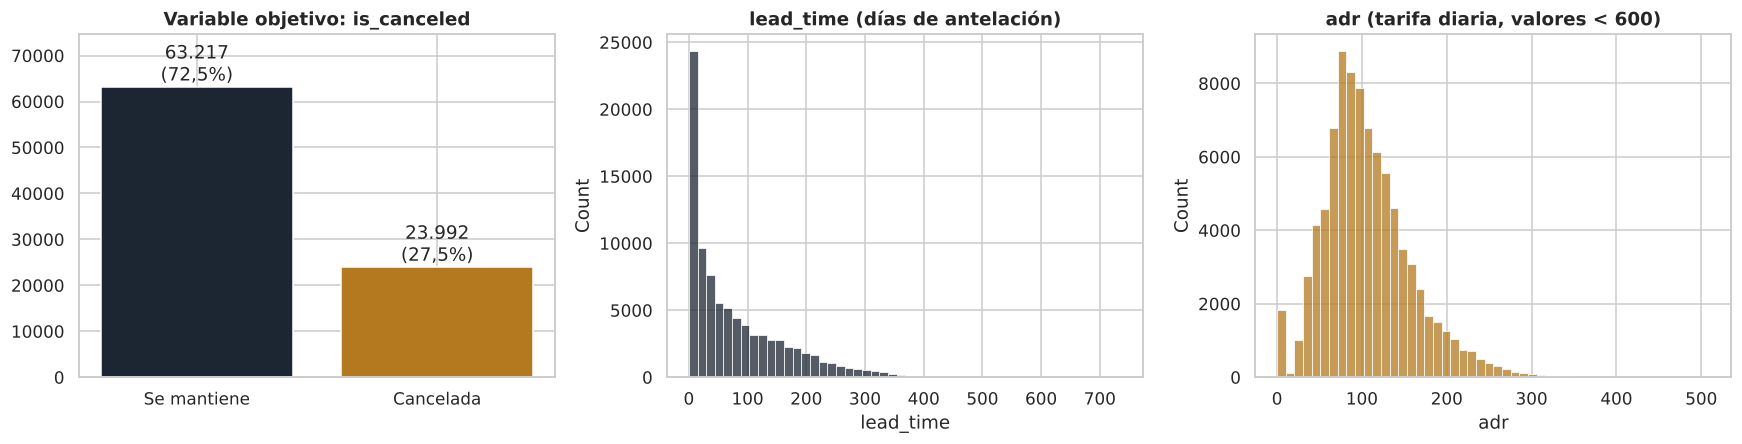

,mean,std,min,50%,max,asimetría,% fuera de IQR
lead_time,79.9400,86.0100,0.0000,49.0000,737.0000,1.4300,2.7300
adr,106.5400,54.8800,0.0000,98.2500,"5,400.0000",11.0300,2.8800
stays_in_weekend_nights,1.0000,1.0300,0.0000,1.0000,19.0000,1.3400,0.2400
stays_in_week_nights,2.6200,2.0400,0.0000,2.0000,50.0000,2.5800,1.7300
adults,1.8800,0.5100,0.0000,2.0000,10.0000,-0.2400,26.0500
children,0.1400,0.4600,0.0000,0.0000,3.0000,3.3700,9.5900
babies,0.0100,0.1000,0.0000,0.0000,2.0000,10.0000,1.0500
previous_cancellations,0.0300,0.3700,0.0000,0.0000,26.0000,34.3300,1.9300
previous_bookings_not_canceled,0.1800,1.7300,0.0000,0.0000,72.0000,20.4500,4.0600
booking_changes,0.2700,0.7100,0.0000,0.0000,18.0000,5.0700,18.1200


In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))

objetivo = df["is_canceled"].map({0: "Se mantiene", 1: "Cancelada"}).value_counts()
ejes[0].bar(objetivo.index, objetivo.values, color=[AZUL, DORADO])
for i, v in enumerate(objetivo.values):
    ejes[0].text(i, v, f"{miles(v)}\n({pct(v / len(df))})", ha="center", va="bottom")
ejes[0].set_title("Variable objetivo: is_canceled")
ejes[0].set_ylim(0, objetivo.max() * 1.18)

sns.histplot(df["lead_time"], bins=50, color=AZUL, ax=ejes[1])
ejes[1].set_title("lead_time (días de antelación)")

sns.histplot(df.loc[df["adr"] < 600, "adr"], bins=50, color=DORADO, ax=ejes[2])
ejes[2].set_title("adr (tarifa diaria, valores < 600)")
plt.tight_layout()
plt.show()

numericas = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
             "babies", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
             "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests"]
resumen = df[numericas].describe().T[["mean", "std", "min", "50%", "max"]]
resumen["asimetría"] = df[numericas].skew()
q1, q3 = df[numericas].quantile(0.25), df[numericas].quantile(0.75)
iqr = q3 - q1
resumen["% fuera de IQR"] = 100 * ((df[numericas] < q1 - 1.5 * iqr) | (df[numericas] > q3 + 1.5 * iqr)).mean()
display(resumen.round(2))

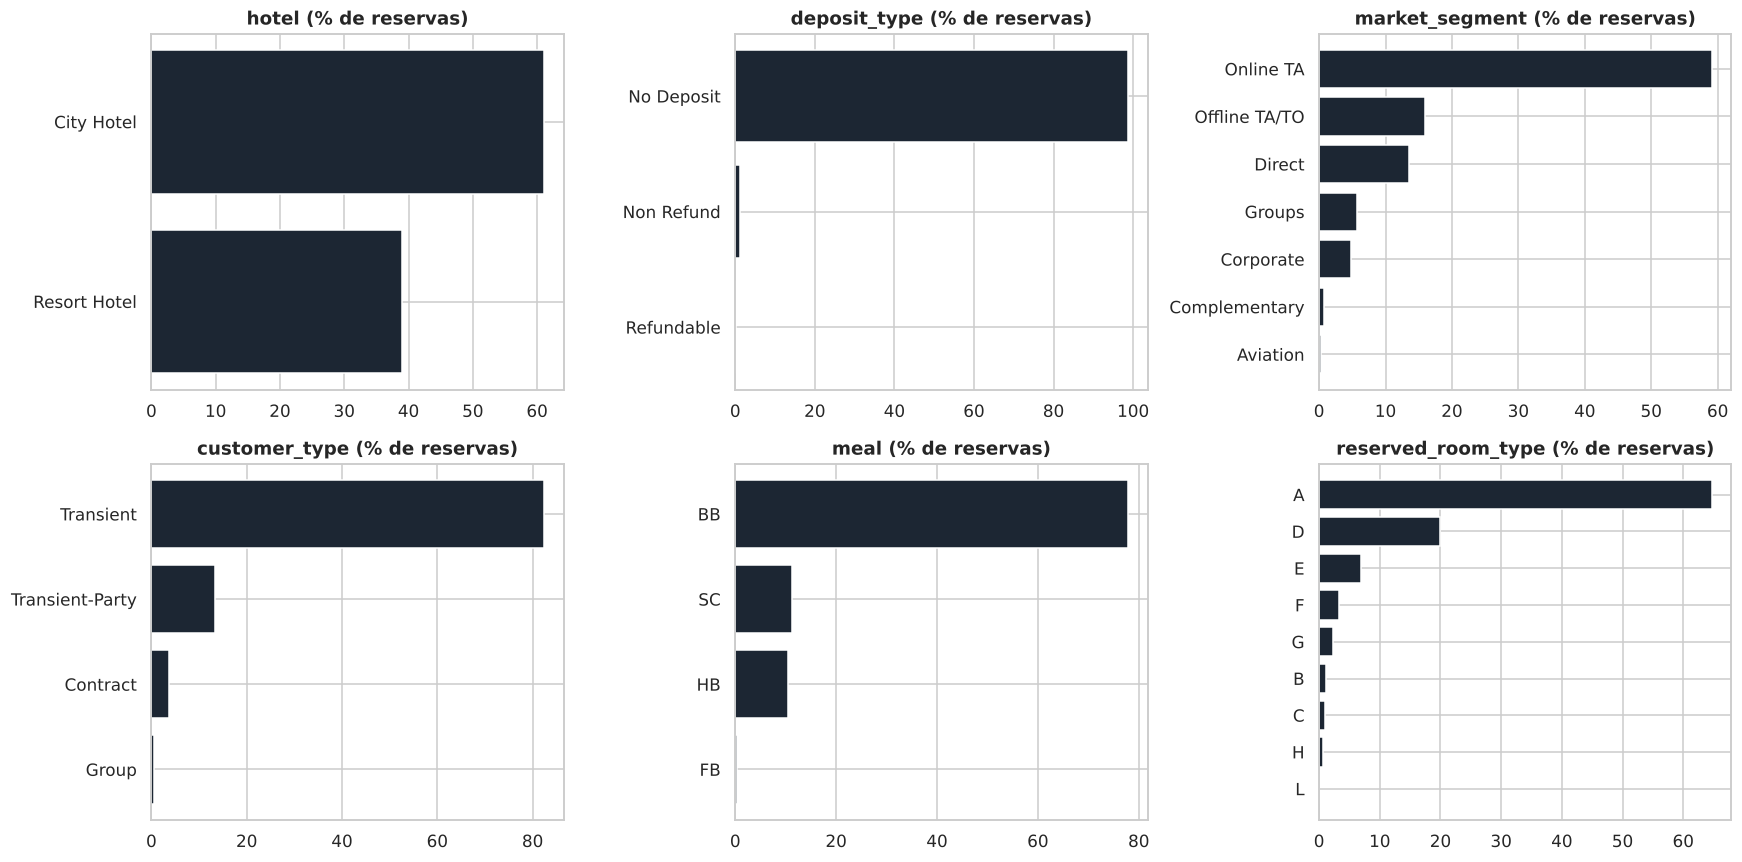

Cardinalidad de las categóricas de alta cardinalidad:
{'country': 178, 'agent': 334}
Países más frecuentes: {'PRT': 31.3, 'GBR': 12.0, 'FRA': 10.1, 'ESP': 8.3, 'DEU': 6.2}


In [6]:
fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(ejes.ravel(), ["hotel", "deposit_type", "market_segment", "customer_type", "meal", "reserved_room_type"]):
    freq = df[col].value_counts(normalize=True).mul(100)
    ax.barh(freq.index[::-1], freq.values[::-1], color=AZUL)
    ax.set_title(f"{col} (% de reservas)")
plt.tight_layout()
plt.show()

print("Cardinalidad de las categóricas de alta cardinalidad:")
print({c: int(df[c].nunique()) for c in ["country", "agent"]})
print("Países más frecuentes:", df["country"].value_counts(normalize=True).head(5).mul(100).round(1).to_dict())

**Hallazgos univariados**
- **Objetivo:** 63.217 reservas se mantienen (72,5%) y 23.992 se cancelan (27,5%). El desbalance es moderado pero mayor que el del primer corte, así que la accuracy sola no sirve: un modelo que siempre responda "se mantiene" acertaría el 72,5% sin detectar ninguna cancelación. Esto lleva a priorizar Recall y F1 de la clase cancelada y a usar pesos de clase.
- **Colas largas:** `lead_time` (asimetría 1,43, mediana de 49 días, máximo 737) y sobre todo `adr` (asimetría 11,03, mediana de 98,25, máximo 5.400) están muy sesgadas a la derecha. Las variables de conteo `previous_cancellations` (34,3), `previous_bookings_not_canceled` (20,5), `days_in_waiting_list` (19,5) y `babies` (10,0) están dominadas por ceros con unos pocos valores altos. Esto justifica la transformación logarítmica y el recorte por IQR de `adr` antes de escalar.
- **IQR no es universal:** el 26% de los valores de `adults` queda "fuera del IQR" solo porque casi todas las reservas tienen 2 adultos y el IQR vale 0; no son valores extremos reales. Por eso el recorte por IQR se aplica solo a `adr`.
- **Composición:** 61% de las reservas son del hotel de ciudad, 98,7% sin depósito, 59% vienen de agencias en línea (Online TA) y 82% son clientes de tipo Transient. Los tipos `Non Refund` (1,2%) y `Refundable` (0,1%) son muy pocos, lo que hace frágil cualquier conclusión sobre ellos.
- **Alta cardinalidad:** `country` tiene 178 categorías y `agent` 334. Portugal concentra el 31,3% de las reservas, seguido de Reino Unido (12,0%) y Francia (10,1%). Un one-hot completo crearía cientos de columnas dispersas, por eso se agrupan en las 10 más frecuentes más `Other`.

### 3.2 Bivariado

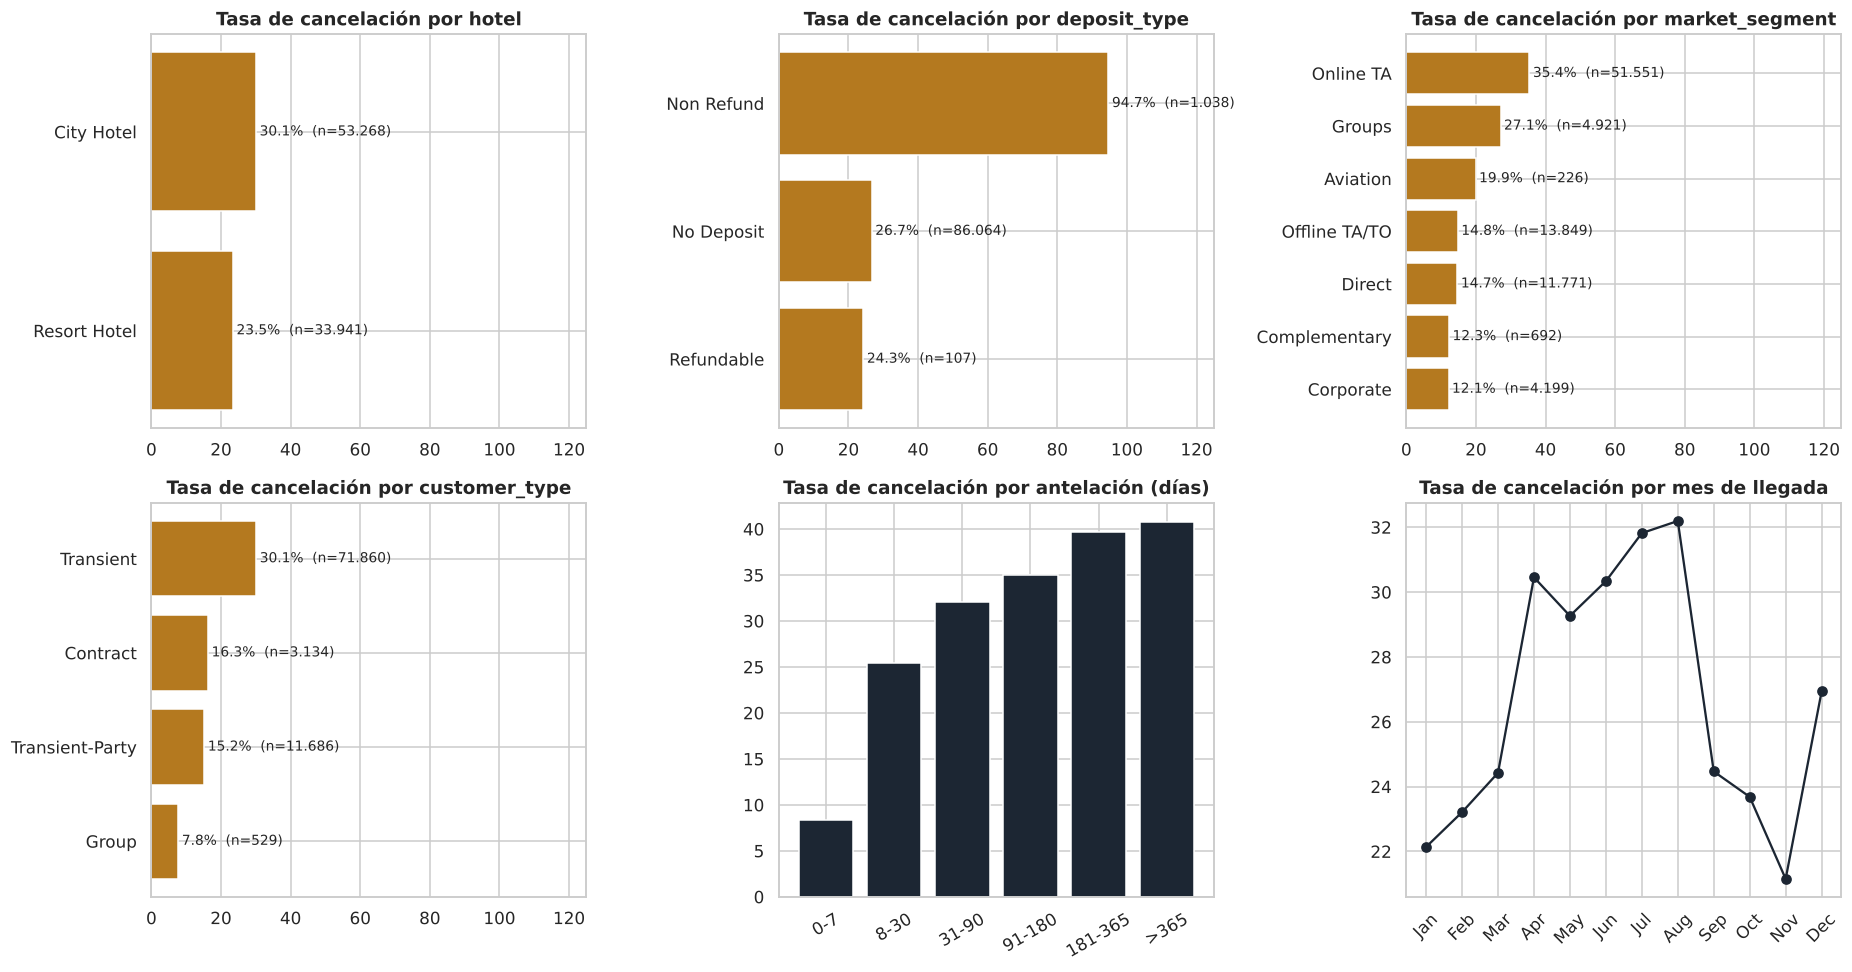

In [7]:
def tasa(col):
    return df.groupby(col)["is_canceled"].agg(["mean", "size"]).rename(columns={"mean": "tasa", "size": "n"})


fig, ejes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(ejes.ravel()[:4], ["hotel", "deposit_type", "market_segment", "customer_type"]):
    t = tasa(col).sort_values("tasa")
    ax.barh(t.index, t["tasa"] * 100, color=DORADO)
    for i, (v, n_) in enumerate(zip(t["tasa"], t["n"])):
        ax.text(v * 100 + 1, i, f"{v * 100:.1f}%  (n={miles(n_)})", va="center", fontsize=9)
    ax.set_xlim(0, 125)
    ax.set_title(f"Tasa de cancelación por {col}")

df["lead_time_rango"] = pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, 1000],
                               labels=["0-7", "8-30", "31-90", "91-180", "181-365", ">365"])
t = tasa("lead_time_rango")
ejes[1, 1].bar(t.index.astype(str), t["tasa"] * 100, color=AZUL)
ejes[1, 1].set_title("Tasa de cancelación por antelación (días)")
ejes[1, 1].tick_params(axis="x", labelrotation=30)

meses = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
t = tasa("arrival_date_month").reindex(meses)
ejes[1, 2].plot([m[:3] for m in meses], t["tasa"] * 100, marker="o", color=AZUL)
ejes[1, 2].set_title("Tasa de cancelación por mes de llegada")
ejes[1, 2].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()
df = df.drop(columns="lead_time_rango")

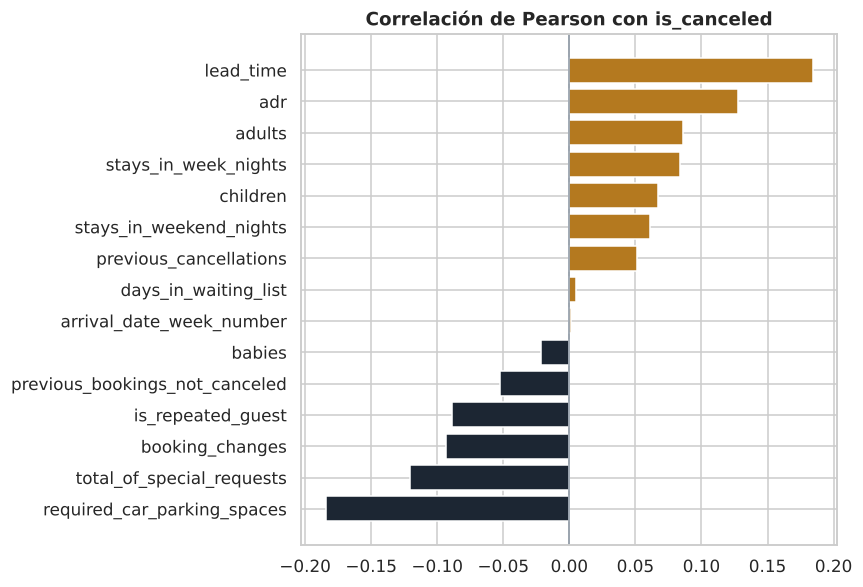

,Comparación,1er corte (dataset crudo),Ahora (dataset limpio)
0,Hotel: ciudad vs resort,"41,7% vs 27,8%","30,1% vs 23,5%"
1,Depósito: Non Refund / No Deposit / Refundable,"99,4% / 28,4% / 22,2%","94,7% / 26,7% / 24,3%"
2,Segmento: Groups / Online TA / Direct,"61,1% / 36,7% / 15,3%","27,1% / 35,4% / 14,7%"
3,Antelación promedio: canceladas vs no,"144,8 vs 80,0 días","105,6 vs 70,2 días"
4,Balance de clases (se mantiene / cancelada),63% / 37%,72% / 28%


In [8]:
correlacion = df[numericas + ["arrival_date_week_number", "is_repeated_guest"]].corrwith(df["is_canceled"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(correlacion.index, correlacion.values, color=[DORADO if v > 0 else AZUL for v in correlacion.values])
ax.axvline(0, color=GRIS, lw=1)
ax.set_title("Correlación de Pearson con is_canceled")
plt.tight_layout()
plt.show()

comparacion = pd.DataFrame([
    ["Hotel: ciudad vs resort", "41,7% vs 27,8%", f"{pct(tasa('hotel').loc['City Hotel', 'tasa'])} vs {pct(tasa('hotel').loc['Resort Hotel', 'tasa'])}"],
    ["Depósito: Non Refund / No Deposit / Refundable", "99,4% / 28,4% / 22,2%",
     " / ".join(pct(tasa('deposit_type').loc[k, 'tasa']) for k in ["Non Refund", "No Deposit", "Refundable"])],
    ["Segmento: Groups / Online TA / Direct", "61,1% / 36,7% / 15,3%",
     " / ".join(pct(tasa('market_segment').loc[k, 'tasa']) for k in ["Groups", "Online TA", "Direct"])],
    ["Antelación promedio: canceladas vs no", "144,8 vs 80,0 días",
     f"{df.loc[df.is_canceled == 1, 'lead_time'].mean():.1f} vs {df.loc[df.is_canceled == 0, 'lead_time'].mean():.1f} días".replace(".", ",")],
    ["Balance de clases (se mantiene / cancelada)", "63% / 37%", f"{pct(1 - df.is_canceled.mean(), 0)} / {pct(df.is_canceled.mean(), 0)}"],
], columns=["Comparación", "1er corte (dataset crudo)", "Ahora (dataset limpio)"])
display(comparacion)

**Hallazgos bivariados**
- **Los duplicados inflaban varios efectos del primer corte.** `Non Refund` tenía 14.587 filas en el crudo y solo quedan 1.038 sin duplicados; `Groups` pasó de unas 19.800 filas a unas 4.900 y su tasa de cancelación cae de 61,1% a 27,1%; la diferencia entre hoteles se reduce de 41,7% vs 27,8% a 30,1% vs 23,5%; y la antelación promedio de las canceladas baja de 144,8 a 105,6 días. Las conclusiones cualitativas se sostienen, las magnitudes no.
- **`deposit_type`:** sigue siendo la señal más fuerte por reserva (94,7% de cancelación en `Non Refund` frente a 26,7% en `No Deposit`), pero aplica solo al 1,2% de las reservas.
- **Antelación:** la tasa de cancelación sube de forma monótona con la antelación, de 8,4% cuando se reserva con 0 a 7 días a 39,6% con 181 a 365 días y 40,8% con más de un año.
- **Canal y cliente:** Online TA cancela 35,4%, frente a 14,7% de las reservas directas y 14,8% de Offline TA/TO; los clientes `Transient` cancelan 30,1% y los de tipo `Group` 7,8%.
- **Estacionalidad:** la cancelación es más alta de abril a agosto (de 30,5% en abril a 32,2% en agosto) y más baja en noviembre (21,1%) y enero (22,1%), por lo que el mes de llegada se trata como categoría.
- **Correlaciones lineales con el objetivo:** moderadas a bajas. `lead_time` (+0,18) y `adr` (+0,13) aumentan el riesgo; `required_car_parking_spaces` (−0,18), `total_of_special_requests` (−0,12), `booking_changes` (−0,09) y `is_repeated_guest` (−0,09) lo reducen. Ninguna variable por sí sola explica la cancelación, lo que apunta a combinar señales con modelos no lineales.
- **Alerta:** ninguna de las reservas que pidieron parqueadero se canceló (tasa 0,0%), y los clientes que hacen solicitudes especiales cancelan menos (33,2% sin solicitudes frente a 16,2% con 3 o más). Estas variables parecen registrarse a medida que la reserva avanza, no necesariamente al momento de reservar; se analiza su efecto en la sección 4.

### 3.3 Multivariado

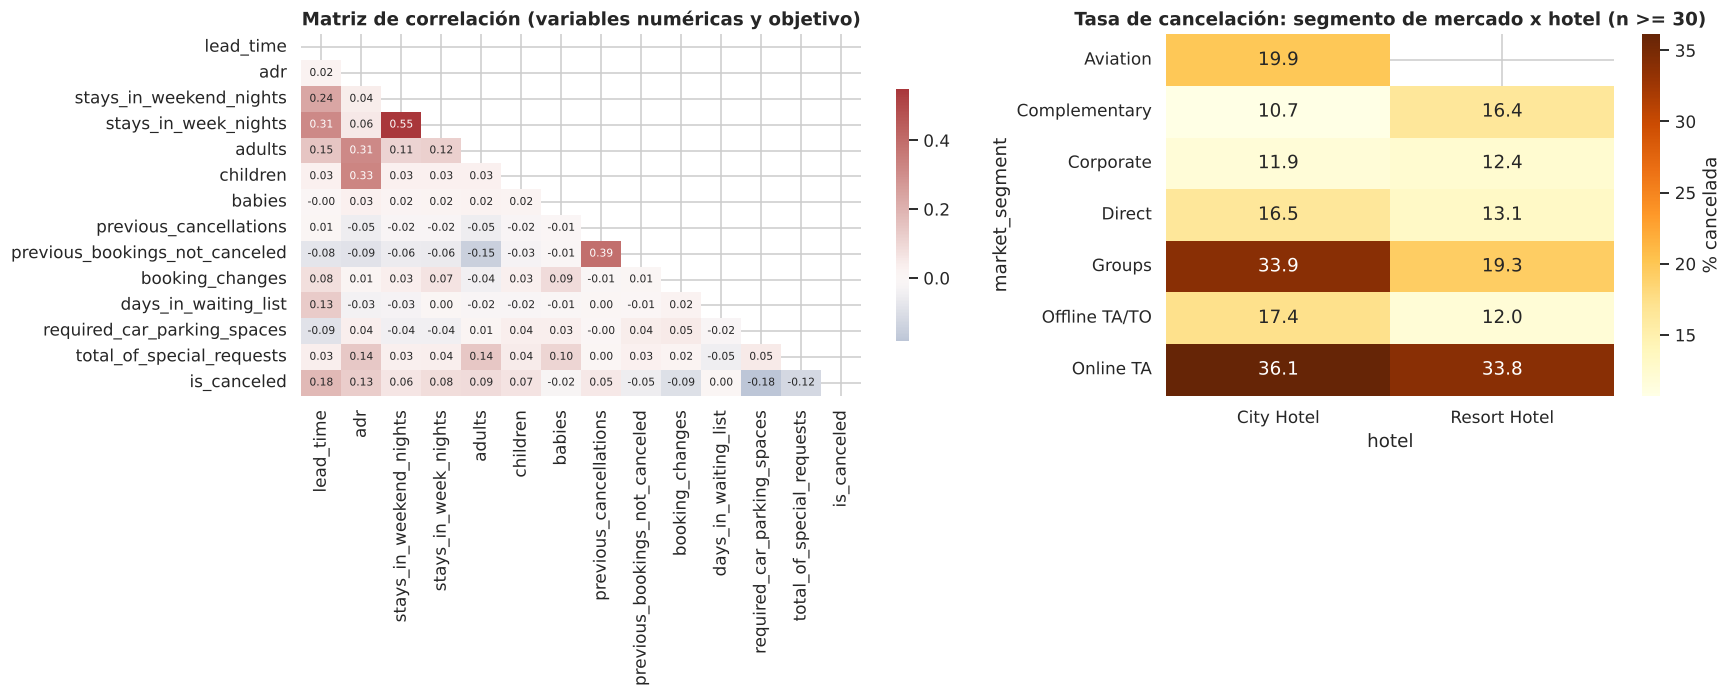

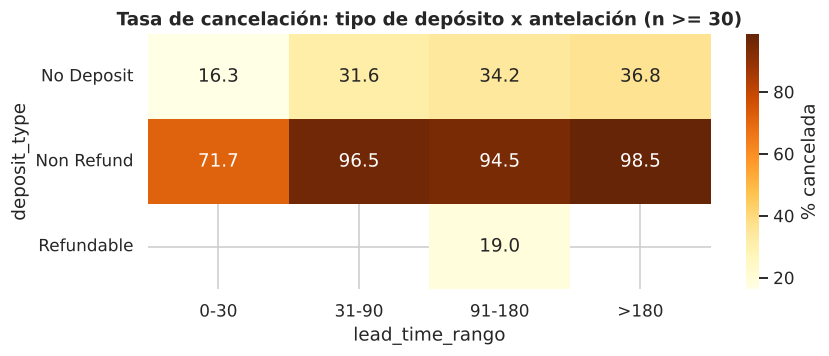

Pares de variables más correlacionados entre sí:


,,|r|
stays_in_week_nights,stays_in_weekend_nights,0.5500
previous_bookings_not_canceled,previous_cancellations,0.3900
children,adr,0.3300
adults,adr,0.3100
stays_in_week_nights,lead_time,0.3100


In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})

corr = df[numericas + ["is_canceled"]].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.7}, ax=ejes[0])
ejes[0].set_title("Matriz de correlación (variables numéricas y objetivo)")

pivote = df.pivot_table(index="market_segment", columns="hotel", values="is_canceled", aggfunc="mean") * 100
conteo = df.pivot_table(index="market_segment", columns="hotel", values="is_canceled", aggfunc="size")
sns.heatmap(pivote.where(conteo >= 30), annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "% cancelada"}, ax=ejes[1])
ejes[1].set_title("Tasa de cancelación: segmento de mercado x hotel (n >= 30)")
plt.tight_layout()
plt.show()

df["lead_time_rango"] = pd.cut(df["lead_time"], [-1, 30, 90, 180, 1000], labels=["0-30", "31-90", "91-180", ">180"])
pivote2 = df.pivot_table(index="deposit_type", columns="lead_time_rango", values="is_canceled", aggfunc="mean", observed=True) * 100
conteo2 = df.pivot_table(index="deposit_type", columns="lead_time_rango", values="is_canceled", aggfunc="size", observed=True)
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.heatmap(pivote2.where(conteo2 >= 30), annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "% cancelada"}, ax=ax)
ax.set_title("Tasa de cancelación: tipo de depósito x antelación (n >= 30)")
plt.tight_layout()
plt.show()
df = df.drop(columns="lead_time_rango")

pares = corr.abs().where(~mascara).stack().sort_values(ascending=False)
pares = pares[pares.index.get_level_values(0) != "is_canceled"]
pares = pares[pares.index.get_level_values(1) != "is_canceled"]
print("Pares de variables más correlacionados entre sí:")
display(pares.head(5).round(2).rename("|r|").to_frame())

**Hallazgos multivariados**
- **Poca colinealidad entre predictores.** La correlación más alta es 0,55 (noches de semana con noches de fin de semana), seguida de 0,39 (cancelaciones previas con reservas previas no canceladas) y 0,33 y 0,31 (`adr` con niños y adultos). No hay colinealidad severa, así que la regresión logística es viable y no hace falta eliminar variables.
- **El efecto del segmento depende del hotel.** Online TA es el segmento más cancelado en ambos hoteles (36,1% en ciudad y 33,8% en resort), pero `Groups` cancela 33,9% en el hotel de ciudad y 19,3% en el resort. Esta interacción es difícil de capturar con un modelo lineal y es un argumento a favor de árboles y ensambles.
- **Depósito y antelación se suman.** Dentro de `No Deposit` la cancelación sube de 16,3% (0 a 30 días) a 36,8% (más de 180 días); en `Non Refund` va de 71,7% a 98,5%. La antelación aumenta el riesgo en ambos tipos de depósito.

**Qué insights sustentan la selección de variables y de modelos**
- Se conservan `lead_time`, `deposit_type`, `market_segment`, `hotel`, `country`, `agent`, `adr`, solicitudes especiales, parqueadero y cambios de reserva, porque cada una muestra una diferencia clara en la tasa de cancelación.
- Las variables de cola larga entran con logaritmo y `adr` con recorte previo.
- Las relaciones lineales débiles, la interacción segmento x hotel y la presencia de variables categóricas de muchas categorías justifican comparar un modelo lineal de referencia contra un árbol y un Random Forest.

## 4. Ingeniería de variables
El orden es: construir las variables nuevas (operaciones fila por fila, sin aprender nada de los datos), dividir en entrenamiento y prueba, y solo entonces ajustar el preprocesamiento con el conjunto de entrenamiento.

**Variables nuevas a partir de la fecha y las cantidades:** mes de llegada, día de la semana de llegada, indicador de llegada en fin de semana, noches totales, huéspedes totales e indicador de que viajan menores. Las columnas originales de año, mes, semana y día se retiran; el año no se usa porque solo toma tres valores y no generaliza a fechas futuras.

In [10]:
datos = engineer_features(df)
y = datos["is_canceled"]
X = datos.drop(columns="is_canceled")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Entrenamiento: {miles(len(X_train))} filas ({pct(y_train.mean())} canceladas)")
print(f"Prueba:        {miles(len(X_test))} filas ({pct(y_test.mean())} canceladas)")

Entrenamiento: 69.767 filas (27,5% canceladas)
Prueba:        17.442 filas (27,5% canceladas)


**Decisión sobre variables que no se conocen al reservar.** El enfoque del primer corte pide usar la información conocida *al momento de la reserva*. `assigned_room_type` se asigna al hacer el check-in, un momento al que una reserva cancelada nunca llega. Se mide cuánto cambia el desempeño con y sin ella, y de paso con y sin las tres variables que se van acumulando después de reservar (`booking_changes`, `required_car_parking_spaces`, `total_of_special_requests`). La medición usa solo el conjunto de entrenamiento.

In [11]:
def auc_cv(columnas):
    Xd = pd.get_dummies(X_train[columnas], dtype=float)
    modelo = RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight="balanced", n_jobs=2, random_state=SEED)
    puntajes = cross_val_score(modelo, Xd, y_train, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="roc_auc")
    return puntajes.mean()


posteriores = ["booking_changes", "required_car_parking_spaces", "total_of_special_requests"]
sensibilidad = pd.DataFrame({
    "Conjunto de variables": [
        "Con assigned_room_type",
        "Conjunto final (sin assigned_room_type)",
        "Sin assigned_room_type ni variables posteriores a la reserva",
    ],
    "ROC-AUC (CV 3 pliegues, solo train)": [
        auc_cv(FEATURE_COLS + ["assigned_room_type"]),
        auc_cv(FEATURE_COLS),
        auc_cv([c for c in FEATURE_COLS if c not in posteriores]),
    ],
})
display(sensibilidad)

,Conjunto de variables,"ROC-AUC (CV 3 pliegues, solo train)"
0,Con assigned_room_type,0.8947
1,Conjunto final (sin assigned_room_type),0.8897
2,Sin assigned_room_type ni variables posteriore...,0.8488


**Lectura de la sensibilidad**
- `assigned_room_type` aporta poco (ROC-AUC de 0,895 con ella frente a 0,890 sin ella), pero se excluye igual porque se asigna en el check-in: una reserva cancelada nunca llega a ese momento y usarla filtra información del resultado.
- Quitar además `booking_changes`, `required_car_parking_spaces` y `total_of_special_requests` baja el ROC-AUC de 0,890 a 0,849. Esas tres variables se mantienen porque formaban parte del plan del primer corte y el hotel las tiene registradas antes de la llegada, pero el desempeño que se informa depende en parte de ellas. Si el modelo debiera predecir en el instante exacto de reservar, el desempeño realista estaría más cerca de 0,85. Se retoma en las limitaciones.

Ahora se ajusta el preprocesamiento con `fit_preprocessing`, que calcula con el conjunto de entrenamiento los límites del recorte IQR de `adr`, las categorías más frecuentes de `country` y `agent`, la media y desviación de la estandarización y las columnas del one-hot. `transform` aplica esos valores ya aprendidos a cualquier conjunto.

In [12]:
prep_base = fit_preprocessing(X_train, y_train)
Z_train = transform(X_train, prep_base)
Z_test = transform(X_test, prep_base)

fuera = int(((X_train["adr"] < prep_base["adr_low"]) | (X_train["adr"] > prep_base["adr_high"])).sum())
print(f"Variables de entrada: {len(FEATURE_COLS)}")
print(f"Columnas tras el preprocesamiento: {Z_train.shape[1]}")
print(f"Recorte IQR de adr (solo con entrenamiento): límites [{prep_base['adr_low']:.2f}, {prep_base['adr_high']:.2f}]")
print(f"Filas de entrenamiento recortadas: {miles(fuera)} ({pct(fuera / len(X_train))})")
print(f"Nulos tras el preprocesamiento: {int(Z_train.isna().sum().sum())}")

grupos = pd.DataFrame({
    "Grupo": ["adr (recorte IQR, log, estandarizar)", "Numéricas con cola larga (log, estandarizar)", "Numéricas (estandarizar)",
              "Binarias (sin cambio)", "Categóricas de baja cardinalidad (one-hot)", f"country y agent (top {TOP_N} + Other, one-hot)"],
    "Variables de entrada": [1, 5, 9, 3, 9, 2],
    "Columnas resultantes": [
        1, 5, 9, 3,
        sum(c.startswith(tuple(f"{v}_" for v in LOW_CAT_COLS)) for c in Z_train.columns),
        sum(c.startswith(tuple(f"{v}_" for v in HIGH_CAT_COLS)) for c in Z_train.columns),
    ],
})
display(grupos)

Variables de entrada: 29
Columnas tras el preprocesamiento: 92
Recorte IQR de adr (solo con entrenamiento): límites [0.00, 227.38]
Filas de entrenamiento recortadas: 1.983 (2,8%)
Nulos tras el preprocesamiento: 0


,Grupo,Variables de entrada,Columnas resultantes
0,"adr (recorte IQR, log, estandarizar)",1,1
1,"Numéricas con cola larga (log, estandarizar)",5,5
2,Numéricas (estandarizar),9,9
3,Binarias (sin cambio),3,3
4,Categóricas de baja cardinalidad (one-hot),9,52
5,"country y agent (top 10 + Other, one-hot)",2,22


**Resultado de la ingeniería de variables**
- `fit_preprocessing` recibe 29 variables de entrada y produce 92 columnas: 1 de `adr`, 5 numéricas con logaritmo, 9 numéricas estandarizadas, 3 binarias, 52 de las categóricas de baja cardinalidad y 22 de `country` y `agent` (10 categorías más `Other` para cada una).
- El recorte IQR de `adr`, con límites calculados solo con entrenamiento ([0; 227,38]), afecta a 1.983 filas de entrenamiento (2,8%); el límite inferior se fija en 0 porque no hay tarifas negativas.
- No quedan nulos tras el preprocesamiento.
- Todo lo que aprende de los datos (límites del IQR, medias y desviaciones del escalado, categorías frecuentes) se ajusta únicamente con entrenamiento y se reajusta dentro de cada pliegue de la validación cruzada, de modo que ni el conjunto de prueba ni los pliegues de validación influyen en el preprocesamiento.

## 5. Reducción de dimensionalidad: PCA y LDA
**Por qué se aplica.** Tras el one-hot el problema tiene casi cien columnas, muchas de ellas dispersas (indicadores de 0 y 1 de categorías poco frecuentes) y varias correlacionadas entre sí. Reducirlas baja el costo de entrenamiento, elimina colinealidad y permite comprobar cuánta señal vive en pocas direcciones. Se prueban las dos técnicas vistas en clase y se comparan con no reducir.

- **PCA** es no supervisada: busca las direcciones de mayor varianza sin mirar la etiqueta. Se conserva el menor número de componentes que explique al menos el 95% de la varianza.
- **LDA** es supervisada: busca la dirección que mejor separa las clases. Con dos clases solo puede producir un componente (clases menos uno).

Ambas se ajustan solo con entrenamiento, y dentro de la validación cruzada se reajustan en cada pliegue.

### 5.1 PCA

,Varianza explicada objetivo,Componentes necesarios
0,80%,16
1,90%,27
2,95%,39
3,99%,57


Componentes seleccionados: 39 de 92 columnas (95,16% de la varianza)


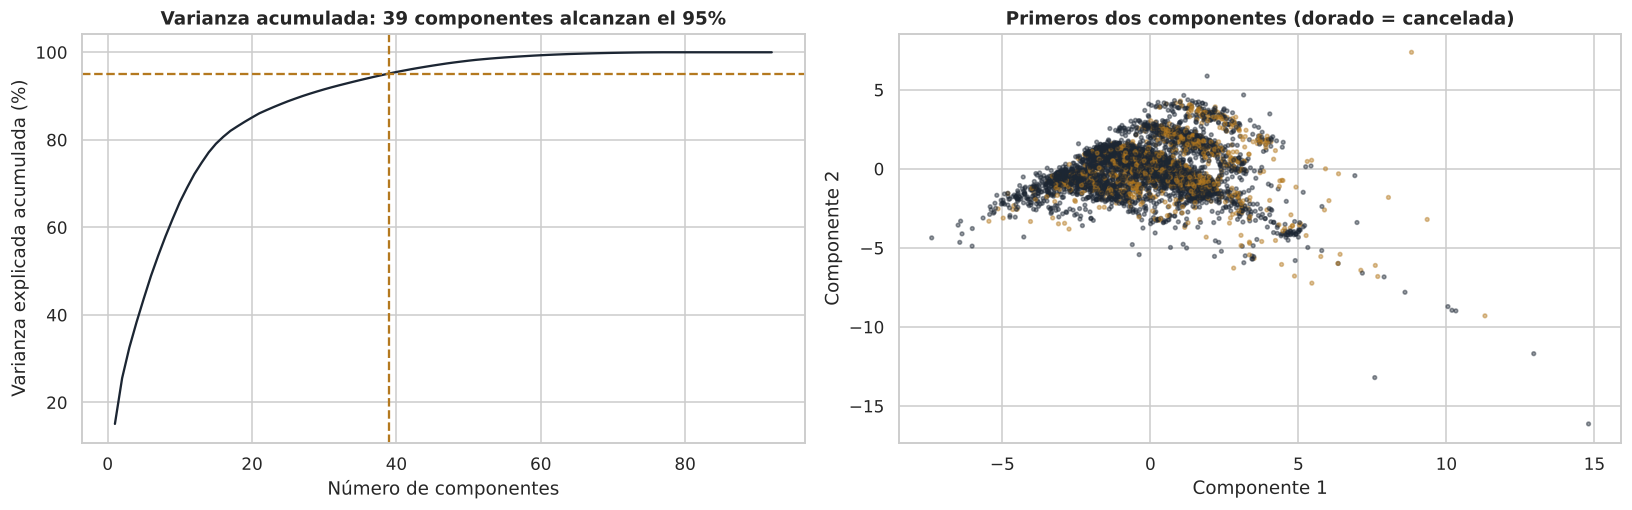

PC1 (15,1%): total_nights (+0.44), stays_in_week_nights (+0.41), stays_in_weekend_nights (+0.37), total_guests (+0.33), lead_time (+0.32)
PC2 (10,5%): total_guests (+0.46), total_nights (-0.38), stays_in_week_nights (-0.35), adults (+0.33), children (+0.33)
PC3 (7,0%): previous_bookings_not_canceled (+0.49), previous_cancellations (+0.40), children (+0.35), required_car_parking_spaces (+0.32), babies (+0.23)


In [13]:
pca_completo = PCA(random_state=SEED).fit(Z_train)
acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

umbrales = pd.DataFrame({
    "Varianza explicada objetivo": ["80%", "90%", "95%", "99%"],
    "Componentes necesarios": [int(np.searchsorted(acumulada, t)) + 1 for t in (0.80, 0.90, 0.95, 0.99)],
})
display(umbrales)
n_95 = int(np.searchsorted(acumulada, 0.95)) + 1
print(f"Componentes seleccionados: {n_95} de {Z_train.shape[1]} columnas ({pct(acumulada[n_95 - 1], 2)} de la varianza)")

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.8))
ejes[0].plot(range(1, len(acumulada) + 1), acumulada * 100, color=AZUL)
ejes[0].axhline(95, color=DORADO, ls="--")
ejes[0].axvline(n_95, color=DORADO, ls="--")
ejes[0].set_xlabel("Número de componentes")
ejes[0].set_ylabel("Varianza explicada acumulada (%)")
ejes[0].set_title(f"Varianza acumulada: {n_95} componentes alcanzan el 95%")

proyeccion = pca_completo.transform(Z_train)[:, :2]
muestra = np.random.RandomState(SEED).choice(len(proyeccion), 6000, replace=False)
colores = np.where(y_train.values[muestra] == 1, DORADO, AZUL)
ejes[1].scatter(proyeccion[muestra, 0], proyeccion[muestra, 1], c=colores, s=6, alpha=0.45)
ejes[1].set_xlabel("Componente 1")
ejes[1].set_ylabel("Componente 2")
ejes[1].set_title("Primeros dos componentes (dorado = cancelada)")
plt.tight_layout()
plt.show()

cargas = pd.DataFrame(pca_completo.components_[:3].T, index=Z_train.columns, columns=["PC1", "PC2", "PC3"])
for pc in cargas.columns:
    print(f"{pc} ({pct(pca_completo.explained_variance_ratio_[int(pc[2]) - 1])}): " +
          ", ".join(f"{k} ({v:+.2f})" for k, v in cargas[pc].reindex(cargas[pc].abs().sort_values(ascending=False).index).head(5).items()))

**Resultado de PCA**
- Se seleccionan **39 componentes de 92 columnas**, que explican el **95,16%** de la varianza (27 componentes bastan para el 90% y 57 para el 99%).
- Los primeros componentes tienen una lectura clara: PC1 (15,1% de la varianza) mide la duración y el tamaño de la estancia (noches y huéspedes), PC2 (10,5%) contrasta el tamaño del grupo con la duración de la estancia, y PC3 (7,0%) recoge el historial del cliente (reservas previas y cancelaciones previas).
- En el plano de los dos primeros componentes las reservas canceladas y no canceladas se solapan casi por completo. Es esperable: PCA busca las direcciones de mayor varianza, no las que separan las clases, y la señal de cancelación puede estar en variables de poca varianza (indicadores raros como `Non Refund`, un país o un agente concretos). El efecto real sobre los modelos se mide en la sección 6.

### 5.2 LDA

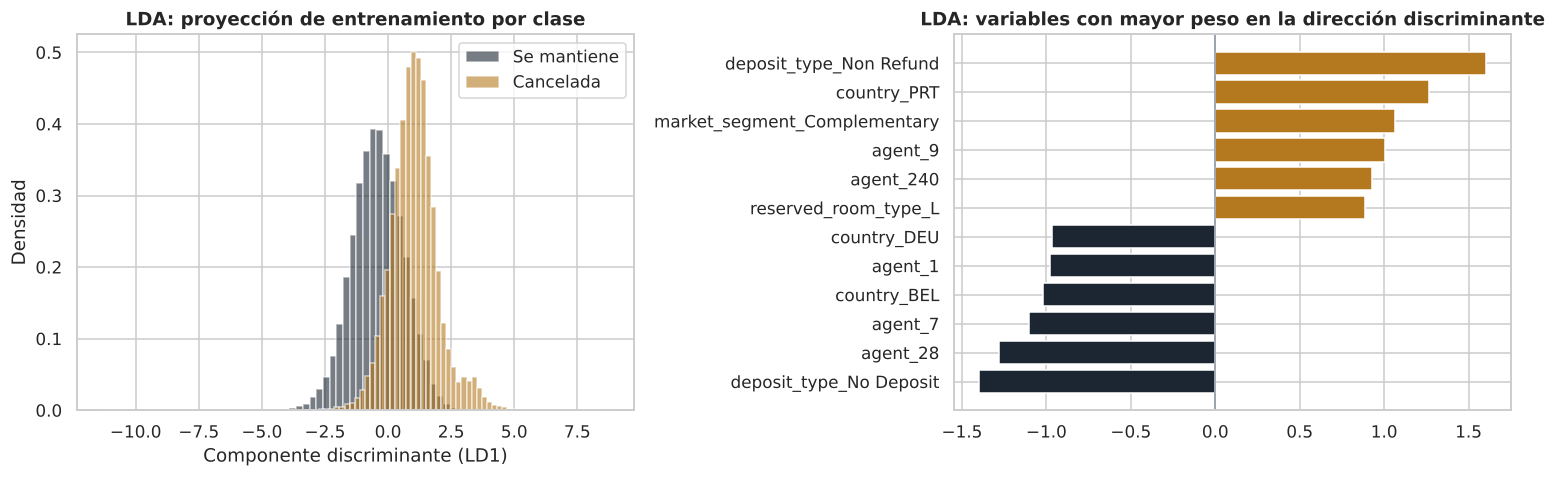

Componentes de LDA: 1
ROC-AUC de LD1 usado como único puntaje (entrenamiento): 0.859
ROC-AUC de LD1 usado como único puntaje (prueba): 0.859


In [14]:
lda = LinearDiscriminantAnalysis(n_components=1).fit(Z_train, y_train)
puntaje_lda = lda.transform(Z_train)[:, 0]
puntaje_lda_test = lda.transform(Z_test)[:, 0]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for clase, nombre, color in [(0, "Se mantiene", AZUL), (1, "Cancelada", DORADO)]:
    ejes[0].hist(puntaje_lda[y_train.values == clase], bins=60, alpha=0.6, color=color, density=True, label=nombre)
ejes[0].set_xlabel("Componente discriminante (LD1)")
ejes[0].set_ylabel("Densidad")
ejes[0].set_title("LDA: proyección de entrenamiento por clase")
ejes[0].legend()

coef_lda = pd.Series(lda.coef_[0], index=Z_train.columns)
top_lda = coef_lda.reindex(coef_lda.abs().sort_values(ascending=False).index).head(12).sort_values()
ejes[1].barh(top_lda.index, top_lda.values, color=[DORADO if v > 0 else AZUL for v in top_lda.values])
ejes[1].axvline(0, color=GRIS, lw=1)
ejes[1].set_title("LDA: variables con mayor peso en la dirección discriminante")
plt.tight_layout()
plt.show()

print(f"Componentes de LDA: {lda.transform(Z_train).shape[1]}")
print(f"ROC-AUC de LD1 usado como único puntaje (entrenamiento): {roc_auc_score(y_train, puntaje_lda):.3f}")
print(f"ROC-AUC de LD1 usado como único puntaje (prueba): {roc_auc_score(y_test, puntaje_lda_test):.3f}")

**Resultado de LDA**
- Con dos clases LDA produce **un único componente** (clases menos uno), así que comprime las 92 columnas en una sola. A diferencia de PCA, ese componente sí se calcula mirando la etiqueta: es la combinación lineal que mejor separa canceladas de no canceladas.
- Usado solo como puntaje, ese componente alcanza un ROC-AUC de 0,859 en entrenamiento y en prueba, es decir, una sola columna conserva buena parte de la señal. Las dos distribuciones por clase se solapan, pero con medias claramente distintas.
- Es una reducción mucho más agresiva que PCA (1 columna frente a 39) y asume que las clases se separan linealmente; su efecto real sobre cada modelo se mide en la sección 6.

## 6. Modelado y evaluación

**Modelos (los tres propuestos en el primer corte).**
- *Logistic Regression*: modelo lineal base, interpretable.
- *Decision Tree*: modelo no lineal basado en reglas, fácil de leer pero propenso al sobreajuste.
- *Random Forest*: ensamble de árboles que promedia sus votos y reduce el sobreajuste de un árbol solo.

**Estrategia.** División estratificada 80/20 (ya hecha en la sección 4) y validación cruzada estratificada de 5 pliegues sobre el entrenamiento para elegir hiperparámetros. El criterio de selección es el F1 de la clase *cancelada*, y se reporta además Accuracy, Precision, Recall, ROC-AUC y matriz de confusión. Cada modelo se entrena tres veces: con las variables preprocesadas completas, con PCA y con LDA, para medir el efecto de la reducción. El conjunto de prueba solo se usa al final para informar resultados, nunca para elegir.

Primero se arman los pliegues de validación cruzada. En cada pliegue el preprocesamiento (y PCA o LDA) se ajusta únicamente con las filas de entrenamiento de ese pliegue.

In [15]:
REDUCCIONES = {"Ninguno": None, "PCA": "PCA", "LDA": "LDA"}
pliegues = {nombre: make_folds(X_train, y_train, reducer=r) for nombre, r in REDUCCIONES.items()}
for nombre, folds in pliegues.items():
    print(f"{nombre:8s} columnas por pliegue: {folds[0][0].shape[1]}")

Ninguno  columnas por pliegue: 91
PCA      columnas por pliegue: 39
LDA      columnas por pliegue: 1


**Tratamiento del desbalance.** El primer corte dejó pendiente evaluar si hacía falta rebalancear. Se compara cada modelo con pesos de clase iguales y con `class_weight="balanced"`, usando los pliegues sin reducción.

In [16]:
filas = []
for nombre, params in [("Logistic Regression", {"C": 1}), ("Decision Tree", {"max_depth": 10, "min_samples_leaf": 20})]:
    for peso in [None, "balanced"]:
        r = cross_validate(nombre, params, pliegues["Ninguno"], class_weight=peso)
        filas.append({"Modelo": nombre, "class_weight": str(peso), "Precision": r["val_precision"],
                      "Recall": r["val_recall"], "F1": r["val_f1"]})
display(pd.DataFrame(filas))

,Modelo,class_weight,Precision,Recall,F1
0,Logistic Regression,None,0.6947,0.5460,0.6114
1,Logistic Regression,balanced,0.5600,0.8236,0.6667
2,Decision Tree,None,0.7174,0.5846,0.6442
3,Decision Tree,balanced,0.5219,0.8970,0.6599


**Lectura de la comparación**
- Con pesos balanceados el Recall sube de 0,55 a 0,82 en la regresión logística y de 0,58 a 0,90 en el árbol, y el F1 mejora en ambos (de 0,611 a 0,667 y de 0,644 a 0,660). El costo es menor Precision (de 0,69 a 0,56 y de 0,72 a 0,52).
- Para el hotel dejar pasar una cancelación real cuesta más que una falsa alarma, así que se acepta esa pérdida de Precision. Se usa `class_weight="balanced"` en los tres modelos.
- No se aplica SMOTE: el desbalance es moderado (la clase minoritaria es el 27,5%) y los pesos de clase consiguen el mismo efecto sin fabricar filas sintéticas.

**Búsqueda de hiperparámetros.** Se explora una cuadrícula pequeña por modelo: se entrena cada combinación en los 5 pliegues y se conserva la de mayor F1 promedio de validación. También se calcula el F1 de entrenamiento para comparar contra el de validación y detectar sobreajuste.

In [17]:
cuadriculas = {
    "Logistic Regression": {"C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"max_depth": [6, 10, 14, None], "min_samples_leaf": [5, 20, 50]},
    "Random Forest": {"max_depth": [20, None], "min_samples_leaf": [2, 5]},
}

busquedas = {}
for nombre, cuadricula in cuadriculas.items():
    for reduccion in REDUCCIONES:
        mejor_comb = grid_search(nombre, cuadricula, pliegues[reduccion])
        busquedas[(nombre, reduccion)] = mejor_comb
        print(f"{nombre:20s} {reduccion:8s} F1 validación = {mejor_comb['val_f1']:.4f}  {mejor_comb['params']}")

Logistic Regression  Ninguno  F1 validación = 0.6667  {'C': 1}


Logistic Regression  PCA      F1 validación = 0.6426  {'C': 0.01}


Logistic Regression  LDA      F1 validación = 0.6599  {'C': 1}


Decision Tree        Ninguno  F1 validación = 0.6752  {'max_depth': 14, 'min_samples_leaf': 20}


Decision Tree        PCA      F1 validación = 0.6214  {'max_depth': None, 'min_samples_leaf': 50}


Decision Tree        LDA      F1 validación = 0.6571  {'max_depth': 6, 'min_samples_leaf': 5}


Random Forest        Ninguno  F1 validación = 0.7150  {'max_depth': None, 'min_samples_leaf': 2}


Random Forest        PCA      F1 validación = 0.6952  {'max_depth': None, 'min_samples_leaf': 5}


Random Forest        LDA      F1 validación = 0.6447  {'max_depth': 20, 'min_samples_leaf': 5}


Con los hiperparámetros elegidos, cada modelo se reentrena con todo el conjunto de entrenamiento (preprocesamiento y reducción ajustados con esas mismas filas) y se evalúa una sola vez en el conjunto de prueba.

In [18]:
preprocesamientos = {}
datos_reducidos = {}
for reduccion, r in REDUCCIONES.items():
    prep = fit_preprocessing(X_train, y_train, r)
    preprocesamientos[reduccion] = prep
    datos_reducidos[reduccion] = (transform(X_train, prep), transform(X_test, prep))

modelos_finales = {}
predicciones = {}
resultados = []
for (nombre, reduccion), b in busquedas.items():
    Z_tr, Z_te = datos_reducidos[reduccion]
    modelo = make_model(nombre, b["params"]).fit(Z_tr, y_train)
    metricas, y_pred, y_prob = evaluate(modelo, Z_te, y_test)
    modelos_finales[(nombre, reduccion)] = modelo
    predicciones[(nombre, reduccion)] = (y_pred, y_prob)
    resultados.append({
        "Modelo": nombre,
        "Reducción": reduccion,
        "Hiperparámetros": ", ".join(f"{k}={v}" for k, v in b["params"].items()),
        "F1 train (CV)": b["train_f1"],
        "F1 validación (CV)": b["val_f1"],
        "Desv. F1 validación": b["val_f1_std"],
        "Accuracy": metricas["Accuracy"],
        "Precision": metricas["Precision"],
        "Recall": metricas["Recall"],
        "F1 test": metricas["F1"],
        "ROC-AUC": metricas["ROC-AUC"],
    })
tabla_resultados = pd.DataFrame(resultados)
tabla_resultados["Brecha F1 (train - test)"] = tabla_resultados["F1 train (CV)"] - tabla_resultados["F1 test"]
display(tabla_resultados)

clave_mejor = max(busquedas, key=lambda k: busquedas[k]["val_f1"])
print(f"\nMejor modelo según F1 de validación cruzada: {clave_mejor[0]} con reducción {clave_mejor[1]}")

,Modelo,Reducción,Hiperparámetros,F1 train (CV),F1 validación (CV),Desv. F1 validación,Accuracy,Precision,Recall,F1 test,ROC-AUC,Brecha F1 (train - test)
0,Logistic Regression,Ninguno,C=1,0.6674,0.6667,0.0037,0.7707,0.5564,0.8210,0.6632,0.8660,0.0041
1,Logistic Regression,PCA,C=0.01,0.6428,0.6426,0.0031,0.7527,0.5337,0.8014,0.6407,0.8486,0.0021
2,Logistic Regression,LDA,C=1,0.6608,0.6599,0.0042,0.7716,0.5600,0.7916,0.6560,0.8590,0.0048
3,Decision Tree,Ninguno,"max_depth=14, min_samples_leaf=20",0.6982,0.6752,0.0045,0.7802,0.5673,0.8470,0.6795,0.8801,0.0187
4,Decision Tree,PCA,"max_depth=None, min_samples_leaf=50",0.6936,0.6214,0.0050,0.7528,0.5353,0.7689,0.6311,0.8416,0.0625
5,Decision Tree,LDA,"max_depth=6, min_samples_leaf=5",0.6618,0.6571,0.0041,0.7665,0.5516,0.8072,0.6554,0.8562,0.0064
6,Random Forest,Ninguno,"max_depth=None, min_samples_leaf=2",0.8771,0.7150,0.0056,0.8275,0.6484,0.8149,0.7222,0.9072,0.1549
7,Random Forest,PCA,"max_depth=None, min_samples_leaf=5",0.9099,0.6952,0.0057,0.8184,0.6448,0.7564,0.6961,0.8913,0.2137
8,Random Forest,LDA,"max_depth=20, min_samples_leaf=5",0.7094,0.6447,0.0065,0.7574,0.5405,0.7893,0.6416,0.8430,0.0678



Mejor modelo según F1 de validación cruzada: Random Forest con reducción Ninguno


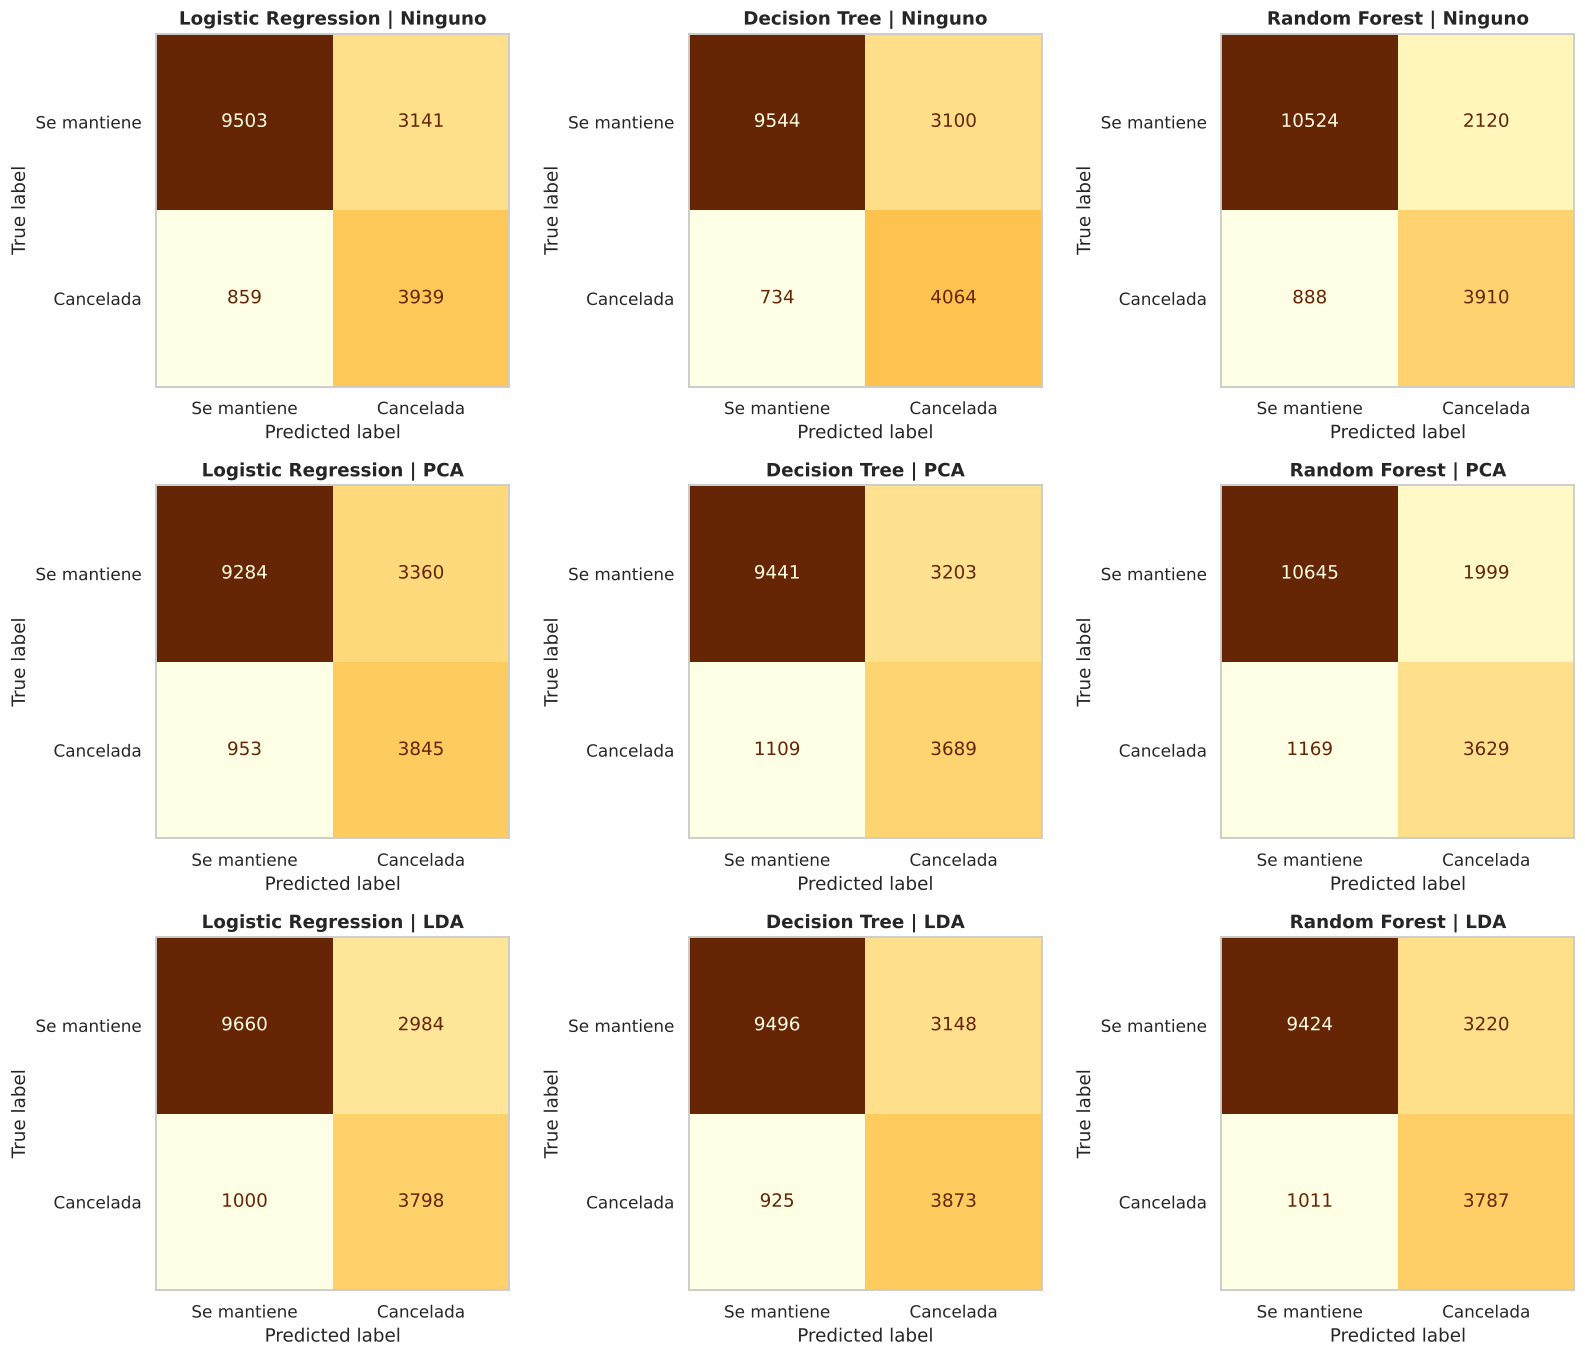

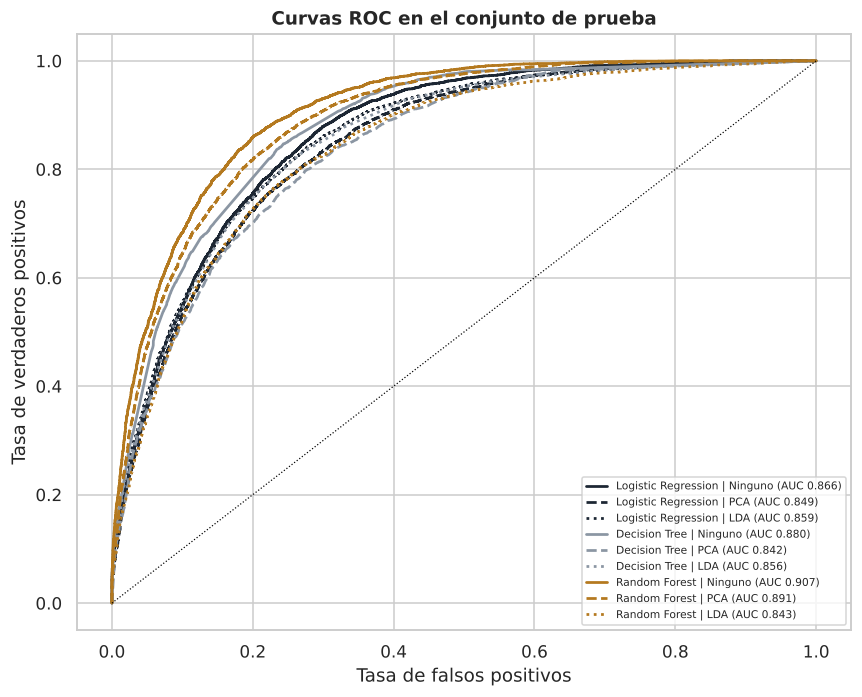

In [19]:
nombres_modelos = list(cuadriculas)
fig, ejes = plt.subplots(3, 3, figsize=(15, 12.5))
for fila, reduccion in enumerate(REDUCCIONES):
    for col, nombre in enumerate(nombres_modelos):
        y_pred, _ = predicciones[(nombre, reduccion)]
        ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Se mantiene", "Cancelada"],
                                                cmap="YlOrBr", colorbar=False, values_format="d", ax=ejes[fila, col])
        ejes[fila, col].set_title(f"{nombre} | {reduccion}")
        ejes[fila, col].grid(False)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
estilos = {"Logistic Regression": AZUL, "Decision Tree": GRIS, "Random Forest": DORADO}
trazos = {"Ninguno": "-", "PCA": "--", "LDA": ":"}
for (nombre, reduccion), (_, y_prob) in predicciones.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, color=estilos[nombre], ls=trazos[reduccion], lw=1.8,
            label=f"{nombre} | {reduccion} (AUC {roc_auc_score(y_test, y_prob):.3f})")
ax.plot([0, 1], [0, 1], color="black", lw=0.8, ls=":")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.legend(loc="lower right", fontsize=7)
plt.tight_layout()
plt.show()

**Lectura de los resultados**
- **Mejor modelo: Random Forest sin reducción** (`max_depth=None`, `min_samples_leaf=2`). Tiene el mayor F1 de validación (0,715 ± 0,006), y en prueba obtiene F1 0,722, Recall 0,815, Precision 0,648, Accuracy 0,828 y ROC-AUC 0,907. Le siguen el árbol de decisión (F1 de validación 0,675; ROC-AUC 0,880) y la regresión logística (0,667; ROC-AUC 0,866).
- **Por qué gana el ensamble:** promedia muchos árboles, captura interacciones no lineales como segmento x hotel y no tiene el sobreajuste de un árbol solo. Su ventaja sobre el árbol es de unos 0,04 de F1 y sobre la regresión logística de unos 0,05.
- **El árbol tiene el mayor Recall (0,847) pero la menor Precision (0,567):** detecta más cancelaciones, a costa de más falsas alarmas. Se eligió por F1 para equilibrar ambos errores.
- **Subajuste.** La regresión logística tiene casi el mismo F1 en entrenamiento y en validación (0,667), pero inferior al de los modelos no lineales: indica una capacidad limitada para esta relación y no un problema de ajuste.
- **Sobreajuste.** El árbol seleccionado tiene una brecha pequeña (F1 de 0,698 en entrenamiento y 0,675 en validación). El Random Forest llega a 0,877 en entrenamiento contra 0,715 en validación: memoriza sus datos de entrenamiento, lo habitual en bosques de árboles profundos. Aun así, el F1 de validación (0,715) y el de prueba (0,722) coinciden, así que esa memorización no se traduce en peor desempeño con datos nuevos.
- **Matriz de confusión del mejor modelo (prueba):** 3.910 cancelaciones detectadas, 888 no detectadas, 2.120 falsas alarmas y 10.524 reservas correctamente clasificadas como no canceladas.

### Impacto de la reducción de dimensionalidad
Cambio en el conjunto de prueba al usar PCA o LDA frente a no reducir, para cada modelo.

In [20]:
base = tabla_resultados[tabla_resultados["Reducción"] == "Ninguno"].set_index("Modelo")
filas = []
for reduccion in ["PCA", "LDA"]:
    sub = tabla_resultados[tabla_resultados["Reducción"] == reduccion].set_index("Modelo")
    for nombre in nombres_modelos:
        filas.append({
            "Modelo": nombre,
            "Reducción": reduccion,
            "Columnas": datos_reducidos[reduccion][0].shape[1],
            "Cambio F1": sub.loc[nombre, "F1 test"] - base.loc[nombre, "F1 test"],
            "Cambio Recall": sub.loc[nombre, "Recall"] - base.loc[nombre, "Recall"],
            "Cambio ROC-AUC": sub.loc[nombre, "ROC-AUC"] - base.loc[nombre, "ROC-AUC"],
        })
impacto = pd.DataFrame(filas)
display(impacto)

,Modelo,Reducción,Columnas,Cambio F1,Cambio Recall,Cambio ROC-AUC
0,Logistic Regression,PCA,39,-0.0226,-0.0196,-0.0174
1,Decision Tree,PCA,39,-0.0483,-0.0782,-0.0384
2,Random Forest,PCA,39,-0.0261,-0.0586,-0.0159
3,Logistic Regression,LDA,1,-0.0073,-0.0294,-0.0070
4,Decision Tree,LDA,1,-0.0241,-0.0398,-0.0239
5,Random Forest,LDA,1,-0.0806,-0.0256,-0.0642


**Impacto de PCA y LDA**
- **PCA (92 a 39 columnas) empeoró los tres modelos:** el F1 de prueba baja 0,023 en la regresión logística, 0,048 en el árbol y 0,026 en el Random Forest; el Recall baja 0,020, 0,078 y 0,059; y el ROC-AUC baja 0,017, 0,038 y 0,016.
- **LDA (92 columnas a 1) también empeoró los tres, pero de forma desigual:** casi no afecta a la regresión logística (F1 -0,007, ROC-AUC -0,007), lo que tiene sentido porque ambos son modelos lineales y LDA ya resume la misma combinación lineal. Afecta más al árbol (F1 -0,024) y sobre todo al Random Forest (F1 -0,081, ROC-AUC -0,064), que con una sola columna no puede explotar interacciones entre variables.
- Una explicación probable para PCA es que el 5% de varianza descartado contiene señal útil en variables de poca varianza, como el tipo de depósito, un país o un agente concreto, que PCA descarta porque no distingue entre varianza y relevancia para la clase. En los árboles también se pierde la posibilidad de dividir directamente por las variables originales.
- Se concluye que la reducción no se justifica para este problema: 92 columnas no son un volumen que exija comprimirlas y el costo en desempeño es claro. El modelo final se entrena sin reducción; PCA y LDA sirvieron para entender la estructura de los datos y confirmar que la señal no se concentra en pocas direcciones.

## 7. Resultados, conclusiones y limitaciones

Modelo seleccionado: Random Forest con reducción Ninguno, max_depth=None, min_samples_leaf=2
Accuracy 0.828 | Precision 0.648 | Recall 0.815 | F1 0.722 | ROC-AUC 0.907
Verdaderos positivos 3,910 | Falsos negativos 888 | Falsos positivos 2,120 | Verdaderos negativos 10,524
De cada 100 cancelaciones reales, el modelo detecta 81.
De cada 100 alertas de cancelación, 65 son cancelaciones reales.
Referencia: predecir siempre 'se mantiene' da accuracy 0.725 y recall 0.


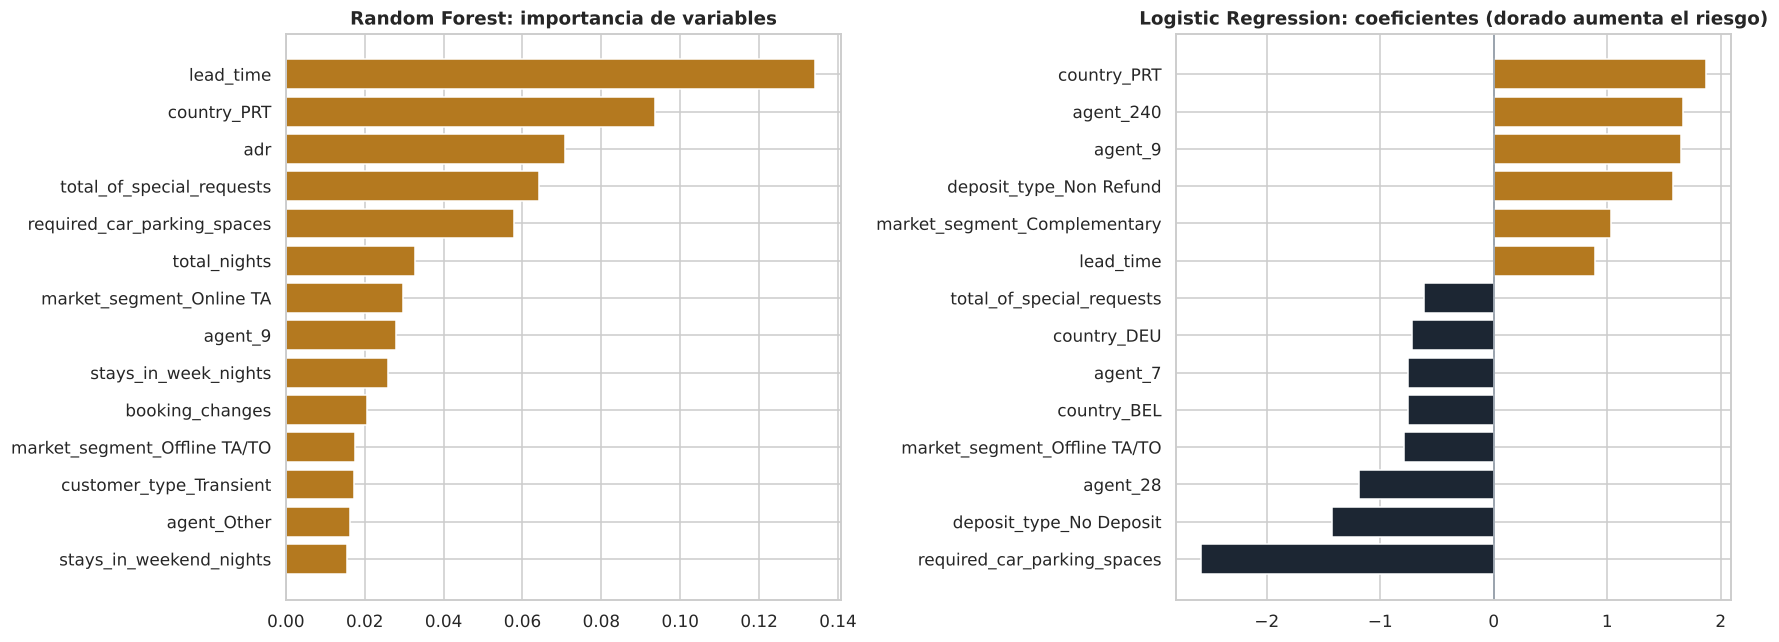

In [21]:
y_pred_final, y_prob_final = predicciones[clave_mejor]
fila_mejor = tabla_resultados[(tabla_resultados["Modelo"] == clave_mejor[0]) & (tabla_resultados["Reducción"] == clave_mejor[1])].iloc[0]

tn = int(((y_test == 0) & (y_pred_final == 0)).sum())
fp = int(((y_test == 0) & (y_pred_final == 1)).sum())
fn = int(((y_test == 1) & (y_pred_final == 0)).sum())
tp = int(((y_test == 1) & (y_pred_final == 1)).sum())
print(f"Modelo seleccionado: {clave_mejor[0]} con reducción {clave_mejor[1]}, {fila_mejor['Hiperparámetros']}")
print(f"Accuracy {fila_mejor['Accuracy']:.3f} | Precision {fila_mejor['Precision']:.3f} | Recall {fila_mejor['Recall']:.3f} | F1 {fila_mejor['F1 test']:.3f} | ROC-AUC {fila_mejor['ROC-AUC']:.3f}")
print(f"Verdaderos positivos {tp:,} | Falsos negativos {fn:,} | Falsos positivos {fp:,} | Verdaderos negativos {tn:,}")
print(f"De cada 100 cancelaciones reales, el modelo detecta {100 * tp / (tp + fn):.0f}.")
print(f"De cada 100 alertas de cancelación, {100 * tp / (tp + fp):.0f} son cancelaciones reales.")
print(f"Referencia: predecir siempre 'se mantiene' da accuracy {1 - y_test.mean():.3f} y recall 0.")

rf = modelos_finales[("Random Forest", "Ninguno")]
importancia = pd.Series(rf.feature_importances_, index=Z_train.columns).sort_values(ascending=False)

lr = modelos_finales[("Logistic Regression", "Ninguno")]
coef = pd.Series(lr.coef_[0], index=Z_train.columns)
coef_top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(14).sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
top = importancia.head(14)[::-1]
ejes[0].barh(top.index, top.values, color=DORADO)
ejes[0].set_title("Random Forest: importancia de variables")
ejes[1].barh(coef_top.index, coef_top.values, color=[DORADO if v > 0 else AZUL for v in coef_top.values])
ejes[1].axvline(0, color=GRIS, lw=1)
ejes[1].set_title("Logistic Regression: coeficientes (dorado aumenta el riesgo)")
plt.tight_layout()
plt.show()

**Respuesta al problema original**
- Sí es posible anticipar con buena capacidad qué reservas se cancelarán. El Random Forest detecta unas **81 de cada 100 cancelaciones reales**, y de cada 100 alertas que emite unas **65 son cancelaciones reales** (las otras 35 son falsas alarmas). Frente a la referencia de predecir siempre "se mantiene" (accuracy 0,725 y Recall 0), el modelo llega a accuracy 0,828 con ROC-AUC 0,907.
- Operativamente esto sirve para cosas de bajo costo ante una falsa alarma, como contactar al cliente para reconfirmar o ajustar un overbooking moderado. No conviene usarlo para rechazar huéspedes de forma automática: una de cada tres alertas es falsa.

**Qué variables pesan más**
- En el Random Forest las más importantes son la antelación (`lead_time`), el país (Portugal), la tarifa (`adr`), las solicitudes especiales y el parqueadero requerido.
- En la regresión logística, aumentan el riesgo reservar desde Portugal, ciertos agentes (el 240 y el 9) y el depósito `Non Refund`; lo reducen requerir parqueadero, tener `No Deposit`, o pasar por el agente 28. Se mantiene el hallazgo del EDA: reservas con mucha antelación, de agencias en línea y sin solicitudes especiales son las de mayor riesgo.
- `deposit_type` es la señal más fuerte por reserva, pero su importancia global es baja porque solo afecta al 1,2% de las reservas.

**Limitaciones**
- **Variables posteriores a la reserva.** Parqueadero, solicitudes especiales y cambios de reserva se registran con el avance de la reserva: ninguna reserva con parqueadero se canceló. Sin ellas el ROC-AUC baja de 0,890 a 0,849, de modo que el desempeño al momento exacto de reservar sería menor al informado.
- **Validación aleatoria, no temporal.** Los datos cubren 2015 a 2017 en dos hoteles de Portugal; el desempeño en otros años, hoteles o países puede ser distinto, y una división por fecha sería una prueba más exigente.
- **Duplicados.** Se eliminaron para evitar fuga entre entrenamiento y prueba, pero el dataset no tiene identificador de reserva: algunas filas idénticas podrían ser reservas reales distintas (por ejemplo, varias habitaciones iguales de un mismo grupo).
- **Categorías raras.** `Non Refund` (1.038 filas) y `Refundable` (107) tienen pocos casos, por lo que sus estimaciones son frágiles.
- **Búsqueda de hiperparámetros acotada.** El mejor Random Forest quedó en el borde de la cuadrícula (profundidad sin límite y mínimo de 2 por hoja); una búsqueda más amplia podría mejorarlo un poco.
- **Probabilidades sin calibrar.** Con `class_weight="balanced"` los puntajes de probabilidad tienden a sobrestimar el riesgo; sirven para ordenar reservas y para clasificar con umbral 0,5, pero no deben leerse como probabilidad real.
- **PCA y LDA sobre variables mezcladas.** Ambas técnicas asumen relaciones lineales y se aplicaron sobre variables numéricas e indicadores de one-hot, donde la varianza (PCA) es una medida discutible de relevancia y una sola dirección (LDA) es una compresión muy fuerte.

**Mejoras futuras**
- Validación temporal y ajuste del umbral de decisión según el costo real de una falsa alarma frente a una cancelación no detectada.
- Probar modelos de boosting (XGBoost, LightGBM) y codificación por objetivo para `country` y `agent`.
- Calibrar las probabilidades (por ejemplo con regresión isotónica) y reentrenar el modelo final con todos los datos antes de ponerlo en producción.
- Separar el modelo en dos: uno con información disponible al reservar y otro que se actualiza con la información posterior (cambios, solicitudes), para usarlo en momentos distintos.

## 8. Artefactos para el despliegue
Se guarda en un solo archivo el preprocesamiento ajustado y el modelo seleccionado, un archivo con las opciones y rangos que usa la aplicación de Streamlit para construir el formulario y una muestra de 1.000 reservas del conjunto de prueba (nunca vistas en el entrenamiento) para la demostración.

In [22]:
carpeta = Path("models")
carpeta.mkdir(exist_ok=True)
save_bundle(carpeta / "best_model.joblib", preprocesamientos[clave_mejor[1]], modelos_finales[clave_mejor])
tabla_resultados.to_csv(carpeta / "resultados_modelos.csv", index=False)

columnas_categoricas = ["hotel", "meal", "market_segment", "distribution_channel", "deposit_type", "customer_type", "reserved_room_type"]
columnas_numericas = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                      "previous_cancellations", "previous_bookings_not_canceled", "booking_changes", "days_in_waiting_list",
                      "required_car_parking_spaces", "total_of_special_requests"]

metadatos = {
    "modelo": f"{clave_mejor[0]} (reducción: {clave_mejor[1]})",
    "hiperparametros": fila_mejor["Hiperparámetros"],
    "metricas_test": {k: float(fila_mejor[k]) for k in ["Accuracy", "Precision", "Recall", "F1 test", "ROC-AUC"]},
    "tasa_cancelacion_base": float(y.mean()),
    "opciones": {c: sorted(X_train[c].astype(str).unique().tolist()) for c in columnas_categoricas},
    "paises_frecuentes": X_train["country"].value_counts().head(TOP_N).index.tolist(),
    "agentes_frecuentes": X_train["agent"].value_counts().head(TOP_N).index.tolist(),
    "numericas": {c: {"min": float(X_train[c].min()), "p99": float(X_train[c].quantile(0.99)),
                      "max": float(X_train[c].max()), "mediana": float(X_train[c].median())} for c in columnas_numericas},
    "importancias": {k: float(v) for k, v in importancia.head(15).items()},
}
with open(carpeta / "app_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

Path("data").mkdir(exist_ok=True)
muestra = df.loc[X_test.index].sample(1000, random_state=SEED)
muestra.to_csv("data/muestra_reservas_test.csv", index=False)
print("Muestra de reservas del conjunto de prueba:", muestra.shape)

paquete = load_bundle(carpeta / "best_model.joblib")
riesgo_app = predict_risk(df.loc[X_test.index].head(200), paquete)
Z_control = transform(X_test.head(200), preprocesamientos[clave_mejor[1]])
riesgo_directo = modelos_finales[clave_mejor].predict_proba(Z_control)[:, 1]
print("El modelo guardado reproduce las probabilidades originales:", bool(np.allclose(riesgo_app, riesgo_directo)))
print("Archivos guardados:", sorted(p.name for p in carpeta.iterdir()))

Muestra de reservas del conjunto de prueba: (1000, 29)


El modelo guardado reproduce las probabilidades originales: True
Archivos guardados: ['app_metadata.json', 'best_model.joblib', 'resultados_modelos.csv']
